# Task 3 — Evaluation, Optimisation and Explainability

| | |
|---|---|
| **Module** | 7006SCN Machine Learning and Big Data |
| **Student** | Manish Saini — SID 17142113 — sainim10@coventry.ac.uk |
| **Pool reference** | 112 |
| **Dataset** | NOAA GHCN-Daily, US stations (`CatLikeIceCream/temperature`, `climate.csv`), prepared in Task 1 |
| **Problem** | Regression: predict `label_TMAX_next`, the next-day maximum temperature (°C) at the same station |
| **Models** | The four models tuned and saved in Task 2 (`results/task2.json`, `models/task2/`) |


## 0 Setup
### 0.1 Environment, paths and run settings
These are the same Windows settings as Tasks 1 and 2: Spark uses the Hadoop helper files in `E:\hadoop`, and its temporary files go to `E:` because `C:` is almost full.

The notebook finds the repository root by looking upwards for `results/task1.json` (with the handoff block) and `results/task2.json`.

In [1]:
# ==============================================================================
# 0.1  Environment, paths and run settings
# REF: Task 2 notebook, cell 0.1 - the same Windows/Hadoop settings and repository-root search are reused
## AI: settings block and  written with AI assistance
# ==============================================================================
import os, sys, json, time, math, platform, tempfile, statistics, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", category=UserWarning)

# ---- Windows only: Hadoop helper files and a temp folder that is not on the full C: drive ----
if os.name == "nt":
    os.environ["HADOOP_HOME"] = os.environ.get("HADOOP_HOME", r"E:\hadoop")
    os.environ["PATH"] = os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
    LOCAL_DIR = os.environ.get("CW_LOCAL_DIR", "E:/spark-tmp")
    os.environ["TEMP"] = os.environ["TMP"] = LOCAL_DIR
else:
    LOCAL_DIR = os.environ.get("CW_LOCAL_DIR", os.path.join(tempfile.gettempdir(), "spark-tmp"))
os.makedirs(LOCAL_DIR, exist_ok=True)


def find_project_root():
    """The repository root: the nearest folder (this one or above) whose results/task1.json has Task 1's
    'handoff' block, whose handoff data exists, and which also holds Task 2's results/task2.json."""
    tried = []
    for candidate in (Path("."), Path(".."), Path("../..")):
        f = candidate / "results" / "task1.json"
        if f.exists():
            tried.append(f.resolve().as_posix())
            h = json.loads(f.read_text()).get("handoff")
            if h and (candidate / h["train_path"]).exists() and (candidate / "results" / "task2.json").exists():
                return candidate
    raise FileNotFoundError(f"No repository root with results/task1.json (handoff) and results/task2.json was "
                            f"found (checked: {tried}). Run Tasks 1 and 2 first, then open this notebook from "
                            "the notebooks/ folder of the repository.")


ROOT = find_project_root()            # relative path to the repository root ("..", when run from notebooks/)

# ---- run settings ----
QUICK_TEST     = False   # True = small samples for a code check only; outputs go to task3/quick_test/
SEED           = 42
REPEATS        = 1 if QUICK_TEST else 3   # each light before/after workload is timed 3 times; the median is used
REPEATS_HEAVY  = 1 if QUICK_TEST else 2   # the 2.5-million-row scoring workload is timed twice per setting
TASKS_PER_CORE = 2                         # Spark tuning guide: 2-3 tasks per CPU core
TUNE_PCT       = 2 if QUICK_TEST else 10   # the same 10% tuning sample as Task 2
CV_FOLDS       = 3                         # the same three year-block folds as Task 2
NOTEBOOK       = "notebooks/task3.ipynb"

# ---- output folders (relative to the repository root) ----
OUT_DIR = ROOT / "task3" / ("quick_test" if QUICK_TEST else "")
RES_DIR = OUT_DIR / "results"
FIG_DIR = OUT_DIR / "figures"
for d in (RES_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def spark_path(p):
    """Spark gets an absolute path; everything printed or saved stays relative to the repository root."""
    return Path(p).resolve().as_posix()


def rel(p):
    return Path(os.path.relpath(Path(p).resolve(), ROOT.resolve())).as_posix()


def show(df, title=None):
    """Display a pandas table with a title (HTML in Jupyter, plain text elsewhere)."""
    if title:
        print(title)
    try:
        from IPython.display import display
        display(df)
    except Exception:
        print(df.to_string(index=False))


print(f"repository root : {ROOT.resolve()}")
print(f"inputs          : results/task1.json (handoff), results/task2.json (models)")
print(f"outputs         : {rel(RES_DIR)}/  {rel(FIG_DIR)}/  results/task3.json")
print(f"Spark temp dir  : {LOCAL_DIR}")
print(f"mode            : {'QUICK TEST - small samples, not for the report' if QUICK_TEST else 'full run'}")

repository root : C:\Users\Manish Saini\sainim10_17142113
inputs          : results/task1.json (handoff), results/task2.json (models)
outputs         : task3/results/  task3/figures/  results/task3.json
Spark temp dir  : E:/spark-tmp
mode            : full run


### 0.2 SparkSession and executor configuration
This is **the Task 2 configuration**, unchanged, so that every "before" time in section 3.1 is measured on the setup that Task 2 really used:

- `local[*]`: one Java process that is both driver and executor, using every laptop core;
- a 4 GB driver (6 GB crashed the JVM in Task 1);
- 32 shuffle partitions, adaptive query execution (AQE) on.

In [2]:
# ==============================================================================
# 0.2  SparkSession and executor configuration
# REF: Task 2 notebook cell 0.2 (same settings); Task 1 notebook section 2 (SparkSession)
#      Changed: app name, and the Spark UI keeps more jobs/stages so this run's timeline can be read back.
# ==============================================================================
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark import SparkContext, StorageLevel
from pyspark.sql import SparkSession, functions as F

# clear any dead Spark/Java session left over from a crash (same block as Tasks 1 and 2)
try:
    SparkSession.getActiveSession().stop()
except Exception:
    pass
SparkContext._active_spark_context = None; SparkContext._gateway = None; SparkContext._jvm = None
SparkSession._instantiatedSession = None; SparkSession._activeSession = None

DRIVER_MEMORY      = os.environ.get("CW_DRIVER_MEMORY", "4g")
SHUFFLE_PARTITIONS = int(os.environ.get("CW_SHUFFLE_PARTITIONS", "32"))

builder = (SparkSession.builder
           .appName("7006SCN-Task3-Optimisation")
           .master("local[*]")                                         # EXPLAIN: one JVM using every CPU core
           .config("spark.driver.memory", DRIVER_MEMORY)
           .config("spark.local.dir", LOCAL_DIR)                       # EXPLAIN: shuffle and spill files
           .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
           .config("spark.sql.adaptive.enabled", "true")
           .config("spark.sql.ansi.enabled", "true")
           .config("spark.ui.retainedJobs", "5000")                    # EXPLAIN: the UI keeps every job of this run
           .config("spark.ui.retainedStages", "5000")
           .config("spark.ui.showConsoleProgress", "false"))
if os.name == "nt":                                                    # EXPLAIN: lets the JVM load hadoop.dll
    hh = os.environ["HADOOP_HOME"].replace("\\", "/")
    builder = builder.config("spark.driver.extraJavaOptions",
                             f"-Djava.library.path={hh}/bin -Dhadoop.home.dir={hh}")
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
sc.setCheckpointDir(Path(LOCAL_DIR, "checkpoints").as_posix())

N_CORES = sc.defaultParallelism
EXECUTOR_CONFIG = {
    "spark_version": spark.version,
    "master": sc.master,
    "cores (default parallelism)": N_CORES,
    "driver_memory": spark.conf.get("spark.driver.memory"),
    "executor": "local mode - the driver JVM is also the executor",
    "shuffle_partitions": spark.conf.get("spark.sql.shuffle.partitions"),
    "adaptive_query_execution": spark.conf.get("spark.sql.adaptive.enabled"),
    "os": platform.platform(),
    "python": platform.python_version(),
}
for k, v in EXECUTOR_CONFIG.items():
    print(f"{k:<28}: {v}")
print(f"\nSpark UI: {sc.uiWebUrl}   <- open this in a browser now and keep it open (see section 3.1.7)")

spark_version               : 4.2.0
master                      : local[*]
cores (default parallelism) : 12
driver_memory               : 4g
executor                    : local mode - the driver JVM is also the executor
shuffle_partitions          : 32
adaptive_query_execution    : true
os                          : Windows-11-10.0.26300-SP0
python                      : 3.14.6

Spark UI: http://10.1.125.75:4040   <- open this in a browser now and keep it open (see section 3.1.7)


## 3.0 Inputs from Task 1 and Task 2
Nothing is retrained here. The notebook loads:

- the training (1970–2015) and test (2016–2023) Parquet files that Task 1 handed over;
- the four fitted pipelines that Task 2 saved, and the model Task 2 recommended.

It also records **how Spark splits the input files into partitions**. That decides how many tasks each stage gets, and therefore what the stage timeline will look like.

In [3]:
# ==============================================================================
# 3.0  Load the Task 1 handoff data and the Task 2 models
# REF: Task 2 notebook cells 1.1 and 1.6 (handoff loading, Task 1 stages rebuilt unfitted);
#      Day05_LiveCoding_Colab > Block 4 (cell-11): PipelineModel.load(path) and reuse without refitting
## AI: input-layout table written with AI assistance
# ==============================================================================
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator

task1 = json.loads((ROOT / "results" / "task1.json").read_text())
task2 = json.loads((ROOT / "results" / "task2.json").read_text())
H = task1["handoff"]
TARGET = H["target_col"]                                            # label_TMAX_next
assert task2.get("models"), "results/task2.json has no 'models' block - run notebooks/task2.ipynb first"
MODEL_PATHS = {n: ROOT / m["model_path"] for n, m in task2["models"].items()}
missing = [n for n, p in MODEL_PATHS.items() if not (p / "metadata").exists()]
assert not missing, f"Task 2 models not found on disk: {missing} - re-run notebooks/task2.ipynb"
RECOMMENDED = task2["recommendation"]["recommended_model"]

train_raw  = spark.read.parquet(spark_path(ROOT / H["train_path"]))
test_raw   = spark.read.parquet(spark_path(ROOT / H["test_path"]))
t1_prep    = PipelineModel.load(spark_path(ROOT / H["preprocessing_model_path"]))
best_model = PipelineModel.load(spark_path(MODEL_PATHS[RECOMMENDED]))
FEATURES_COL = t1_prep.stages[-1].getOutputCol()                    # 'features'

from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
imp_m, idx_m, ohe_m, va_t1, scaler_m = t1_prep.stages
MODEL_COLS = ["ID", "date", "YEAR"] + list(idx_m.getInputCols()) + [TARGET] + list(imp_m.getInputCols())


def make_preprocessing_stages():
    """New, UNFITTED copies of Task 1's five stages with Task 1's exact settings (same as Task 2 cell 1.6)."""
    return [
        Imputer(inputCols=imp_m.getInputCols(), outputCols=imp_m.getOutputCols(), strategy=imp_m.getStrategy()),
        StringIndexer(inputCols=idx_m.getInputCols(), outputCols=idx_m.getOutputCols(),
                      handleInvalid=idx_m.getHandleInvalid(), stringOrderType=idx_m.getStringOrderType()),
        OneHotEncoder(inputCols=ohe_m.getInputCols(), outputCols=ohe_m.getOutputCols(),
                      dropLast=ohe_m.getDropLast(), handleInvalid=ohe_m.getHandleInvalid()),
        VectorAssembler(inputCols=va_t1.getInputCols(), outputCol=va_t1.getOutputCol(),
                        handleInvalid=va_t1.getHandleInvalid()),
        StandardScaler(inputCol=scaler_m.getInputCol(), outputCol=scaler_m.getOutputCol(),
                       withMean=scaler_m.getWithMean(), withStd=scaler_m.getWithStd()),
    ]



def input_layout(split, df, folder):
    """Parquet files on disk -> Spark input partitions -> rows per partition."""
    sizes = sorted((f.stat().st_size for f in Path(folder).glob("*.parquet")), reverse=True)
    per_part = (df.groupBy(F.spark_partition_id().alias("partition")).count().toPandas()["count"])
    return {"Split": split, "Rows": int(per_part.sum()), "Parquet files": len(sizes),
            "File size min-max (MB)": f"{sizes[-1] / 1e6:.2f}-{sizes[0] / 1e6:.2f}",
            "Spark input partitions": df.rdd.getNumPartitions(), "Cores": N_CORES,
            "Rows per partition (min / median / max)": f"{per_part.min():,} / {int(per_part.median()):,} / {per_part.max():,}",
            "Largest / median partition": round(per_part.max() / per_part.median(), 2)}


INPUT_LAYOUT = pd.DataFrame([input_layout("train", train_raw, ROOT / H["train_path"]),
                             input_layout("test", test_raw, ROOT / H["test_path"])])
N_TRAIN, N_TEST = (int(x) for x in INPUT_LAYOUT["Rows"])
assert (N_TRAIN, N_TEST) == (H["train_rows"], H["test_rows"]), "row counts differ from results/task1.json"
show(INPUT_LAYOUT, "Table 3.0  How Spark reads the Task 1 handoff files")
INPUT_LAYOUT.to_csv(RES_DIR / "task3_input_layout.csv", index=False)

print(f"models loaded from results/task2.json : {list(MODEL_PATHS)}")
print(f"recommended in Task 2                 : {RECOMMENDED} "
      f"(test RMSE {task2['models'][RECOMMENDED]['test_metrics']['RMSE']:.3f} deg C)")

Table 3.0  How Spark reads the Task 1 handoff files


,Split,Rows,Parquet files,File size min-max (MB),Spark input partitions,Cores,Rows per partition (min / median / max),Largest / median partition
0,train,2555512,23,0.78-2.42,11,12,"145,462 / 237,354 / 331,084",1.39
1,test,433788,12,0.22-0.81,12,12,"11,168 / 37,868 / 53,961",1.42


models loaded from results/task2.json : ['LinearRegression', 'RandomForestRegressor', 'FMRegressor', 'GBTRegressor']
recommended in Task 2                 : GBTRegressor (test RMSE 3.853 deg C)


## 3.1 Spark UI interpretation and optimisation
### 3.1.1 How the timings are measured
The method is the same for every change:

1. **Read before changing.** The workload is run once with the Task 2 settings. 
2. **One change at a time.** Each change is compared against the Task 2 settings, never against another change.

| Column | Meaning |
|---|---|
| Duration (s) | Stage start to stage end, as on the Stages page |
| Task time (s) | Total time all tasks spent working |
| Median / max task (s) | From the stage's *Summary Metrics*; max ÷ median > 1.5 means one task holds the stage up (**skew**) |
| Rows per task | Smallest and largest number of rows a task read |
| Shuffle write / read (MB) | Data moved between stages (**shuffle**) |
| Spill (MB) | Data pushed out of memory to disk while a task ran (**spill**) |
| Core use (%) | Task time ÷ (wall time × cores): how busy the cores were |

In [4]:
# ==============================================================================
# 3.1.1  Spark UI helpers: job groups, REST API, stage and job tables, fair timing
# REF: Week 5 lecture "Performance Tuning & Debugging" (reading the Jobs/Stages pages);
#      Spark docs "Monitoring and Instrumentation" (REST API /applications/[app-id]/jobs, /stages,
#      /stages/[stage-id]/[attempt-id]/taskSummary, /taskList, /storage/rdd, /executors)
## AI: REST-API helpers, stage/job tables and the alternating timing harness written with AI assistance
# ==============================================================================
import urllib.request
from datetime import datetime

_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))    # EXPLAIN: localhost never via a proxy


def ui_api(path, timeout=30):
    """GET /api/v1/applications/<this app>/<path> from the live Spark UI; None if it cannot be reached."""
    port = (sc.uiWebUrl or ":4040").rsplit(":", 1)[-1]
    for base in dict.fromkeys([sc.uiWebUrl, f"http://localhost:{port}", f"http://127.0.0.1:{port}"]):
        if not base:
            continue
        try:
            with _opener.open(f"{base}/api/v1/applications/{sc.applicationId}/{path}", timeout=timeout) as r:
                return json.loads(r.read().decode("utf-8"))
        except Exception:
            continue
    return None


def _ts(s):
    return datetime.strptime(s.replace("GMT", "+0000"), "%Y-%m-%dT%H:%M:%S.%f%z")


def run_timed(group, description, fn):
    """Run fn() inside a named Spark job group and return its wall-clock time in seconds."""
    sc.setJobGroup(group, description)
    try:
        t0 = time.perf_counter()
        fn()
        return time.perf_counter() - t0
    finally:
        sc.setLocalProperty("spark.jobGroup.id", None)
        sc.setLocalProperty("spark.job.description", None)


def group_jobs(group, wait_s=20):
    """Finished jobs of one job group (waits briefly until the UI has recorded the last job)."""
    deadline = time.time() + wait_s
    while True:
        jobs = [j for j in (ui_api("jobs") or []) if j.get("jobGroup") == group]
        if (jobs and all(j.get("status") != "RUNNING" for j in jobs)) or time.time() > deadline:
            return sorted(jobs, key=lambda j: j["jobId"])
        time.sleep(0.5)


def _quantiles(summary, *keys):
    v = summary
    for k in keys:
        v = (v or {}).get(k)
    return v if isinstance(v, list) and len(v) == 3 else [0, 0, 0]


def group_stages(group, detail_top=4):
    """One row per stage that ran in the job group. Task-level summaries (median/max task, rows per task)
    are fetched for the longest `detail_top` stages, which is where a bottleneck would show."""
    jobs = group_jobs(group)
    job_of = {sid: j["jobId"] for j in jobs for sid in j.get("stageIds", [])}
    stages = {}
    for s in (ui_api("stages?status=complete") or []):
        if s["stageId"] in job_of:
            stages[(s["stageId"], s["attemptId"])] = s
    rows = []
    for (sid, att), s in sorted(stages.items()):
        rows.append({"Job": job_of[sid], "Stage": sid, "Attempt": att,
                     "Action": s.get("name", "").split(" at ")[0],
                     "Tasks": s["numTasks"],
                     "Duration (s)": round((_ts(s["completionTime"]) - _ts(s["submissionTime"])).total_seconds(), 2),
                     "Task time (s)": round(s["executorRunTime"] / 1000, 2),
                     "Input rows": s.get("inputRecords", 0),
                     "Shuffle write (MB)": round(s.get("shuffleWriteBytes", 0) / 1e6, 2),
                     "Shuffle read (MB)": round(s.get("shuffleReadBytes", 0) / 1e6, 2),
                     "Spill (MB)": round((s.get("memoryBytesSpilled", 0) + s.get("diskBytesSpilled", 0)) / 1e6, 2),
                     "GC (s)": round(s.get("jvmGcTime", 0) / 1000, 2)})
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df["Median task (s)"] = np.nan; df["Max task (s)"] = np.nan; df["Max / median"] = np.nan
    df["Rows per task (min-max)"] = ""
    for i in df.nlargest(detail_top, "Duration (s)").index:
        q = ui_api(f"stages/{df.at[i, 'Stage']}/{df.at[i, 'Attempt']}/taskSummary?quantiles=0.0,0.5,1.0") or {}
        run = _quantiles(q, "executorRunTime")
        recs = _quantiles(q, "inputMetrics", "recordsRead")
        if not any(recs):
            recs = _quantiles(q, "shuffleReadMetrics", "readRecords")
        df.at[i, "Median task (s)"] = round(run[1] / 1000, 3)
        df.at[i, "Max task (s)"] = round(run[2] / 1000, 3)
        df.at[i, "Max / median"] = round(run[2] / run[1], 2) if run[1] else np.nan
        df.at[i, "Rows per task (min-max)"] = f"{int(recs[0]):,}-{int(recs[2]):,}" if any(recs) else ""
    return df


def group_jobs_table(group):
    rows = []
    for j in group_jobs(group):
        dur = (_ts(j["completionTime"]) - _ts(j["submissionTime"])).total_seconds()
        rows.append({"Job": j["jobId"], "Action": j.get("name", "").split(" at ")[0],
                     "Duration (s)": round(dur, 2), "Stages run": j.get("numCompletedStages", 0),
                     "Stages skipped": j.get("numSkippedStages", 0), "Tasks": j.get("numCompletedTasks", 0)})
    return pd.DataFrame(rows)


def core_use(stages_df, wall_s):
    """Share of the available core-seconds that tasks actually used."""
    if stages_df.empty or not wall_s:
        return float("nan")
    return round(100 * stages_df["Task time (s)"].sum() / (wall_s * N_CORES), 1)


def compare(name, before_fn, after_fn, repeats, after_first=False):
    """Time before_fn and after_fn in turns (B, A, B, A, ...); each run gets its own job group."""
    runs, groups = {"before": [], "after": []}, {"before": [], "after": []}
    order = ("after", "before") if after_first else ("before", "after")
    for i in range(1, repeats + 1):
        for which in order:
            g = f"t3_{name}_{which}_{i}"
            runs[which].append(run_timed(g, f"T3.1 {name}: {which.upper()} run {i}",
                                         before_fn if which == "before" else after_fn))
            groups[which].append(g)
            print(f"  {name:<12} {which:<6} run {i}: {runs[which][-1]:6.2f} s", flush=True)
    return runs, groups


UI_REACHABLE = ui_api("environment") is not None
ex = (ui_api("executors") or [{}])[0]
RESOURCES = {"cores": ex.get("totalCores", N_CORES),
             "storage_memory_mb": round(ex.get("maxMemory", 0) / 2**20),
             "driver_memory": spark.conf.get("spark.driver.memory")}
print(f"Spark UI REST API reachable: {UI_REACHABLE}  ({sc.uiWebUrl}/api/v1/applications/{sc.applicationId})")
print(f"Executors page: {RESOURCES['cores']} cores, {RESOURCES['storage_memory_mb']:,} MB storage memory "
      f"(part of the {RESOURCES['driver_memory']} driver heap that can hold cached data)")
if not UI_REACHABLE:
    print("WARNING: the Spark UI could not be read - timings still run, but the stage tables will be empty.")

Spark UI REST API reachable: True  (http://10.1.125.75:4040/api/v1/applications/local-1792680147503)
Executors page: 12 cores, 2,278 MB storage memory (part of the 4g driver heap that can hold cached data)


### 3.1.2 Baseline: what the stage timeline shows

Here it runs exactly as Task 2 would have run it: nothing is cached, and the input keeps its original partitions. The two tables below are the **Jobs** and **Stages** pages of the Spark UI for this one run.

In [5]:
# ==============================================================================
# 3.1.2  Baseline evaluation job (Task 2 settings) and its stage timeline
# REF: Day06_Regression_LiveCoding_Solutions_Colab > cell-9 [Day 6]: RegressionEvaluator(metricName=...)
#      Changed: the same metrics as Table 2.3, run as one job group so the Spark UI timeline can be read
## AI: evaluation workload and diagnosis summary written with AI assistance
# ==============================================================================
EVAL_COLS = ["ID", "state_code", TARGET, "prediction"]               # the only columns the metrics read


def evaluation_workload(pred):
    """Five metrics + an error table by state: 6 Spark actions on the same predictions."""
    out = {m: RegressionEvaluator(labelCol=TARGET, predictionCol="prediction", metricName=m).evaluate(pred)
           for m in ("rmse", "mae", "r2", "var")}
    err = F.col(TARGET) - F.col("prediction")
    out["max_abs_error"] = pred.select(F.max(F.abs(err))).first()[0]
    out["by_state"] = (pred.groupBy("state_code")
                           .agg(F.count(F.lit(1)).alias("rows"), F.sqrt(F.avg(err * err)).alias("rmse"))
                           .toPandas())
    return out


RESULT = {}


def eval_before():
    RESULT["before"] = evaluation_workload(best_model.transform(test_raw))      # EXPLAIN: nothing cached


BASE_WALL = run_timed("t3_baseline", "T3.1 BASELINE: evaluate the recommended model, Task 2 settings", eval_before)
BASE_JOBS, BASE_STAGES = group_jobs_table("t3_baseline"), group_stages("t3_baseline", detail_top=6)
show(BASE_JOBS, f"Table 3.1a  Baseline jobs ({BASE_WALL:.1f} s wall time) - the Jobs page for this run")
show(BASE_STAGES, "Table 3.1b  Baseline stages - the Stages page for this run")
BASE_JOBS.to_csv(RES_DIR / "task3_baseline_jobs.csv", index=False)
BASE_STAGES.to_csv(RES_DIR / "task3_baseline_stages.csv", index=False)

# ---- diagnosis, read from the two tables above ----
DIAG = {"wall_s": round(BASE_WALL, 2)}
if not BASE_STAGES.empty:
    scans = BASE_STAGES[BASE_STAGES["Input rows"] >= N_TEST]                       # stages that read every test row
    top = scans.loc[scans["Duration (s)"].idxmax()] if len(scans) else None       # the slowest full scan
    DIAG.update({
        "jobs": len(BASE_JOBS), "full_scans": len(scans),
        "scan_time_s": round(scans["Duration (s)"].sum(), 2),
        "scan_share_pct": round(100 * scans["Duration (s)"].sum() / max(BASE_STAGES["Duration (s)"].sum(), 1e-9), 1),
        "scan_tasks": int(scans["Tasks"].median()) if len(scans) else None,
        "skew_max_over_median": float(top["Max / median"]) if top is not None else None,
        "skew_rows_per_task": top["Rows per task (min-max)"] if top is not None else None,
        "shuffle_write_mb": round(BASE_STAGES["Shuffle write (MB)"].sum(), 2),
        "spill_mb": round(BASE_STAGES["Spill (MB)"].sum(), 2),
        "gc_pct": round(100 * BASE_STAGES["GC (s)"].sum() / max(BASE_STAGES["Task time (s)"].sum(), 1e-9), 1),
        "core_use_pct": core_use(BASE_STAGES, BASE_WALL),
    })
    print("\nWhat the timeline shows")
    print(f"- Recomputation: {DIAG['full_scans']} of the {DIAG['jobs']} jobs re-read all {N_TEST:,} test rows and "
          f"re-ran the 5 preprocessing stages + {RECOMMENDED}; these scans are {DIAG['scan_share_pct']}% of stage time.")
    print(f"- Skew: in the slowest scan stage the longest task took {DIAG['skew_max_over_median']}x the median task "
          f"(rows per task {DIAG['skew_rows_per_task']}), with {DIAG['scan_tasks']} tasks for {N_CORES} cores.")
    print(f"- Shuffle: {DIAG['shuffle_write_mb']} MB in total - only the small error table by state is shuffled.")
    print(f"- Spill: {DIAG['spill_mb']} MB; GC: {DIAG['gc_pct']}% of task time - memory is not the bottleneck.")
    print(f"- Core use: {DIAG['core_use_pct']}% of the {N_CORES} cores over the {BASE_WALL:.1f} s run.")

Table 3.1a  Baseline jobs (38.6 s wall time) - the Jobs page for this run


,Job,Action,Duration (s),Stages run,Stages skipped,Tasks
0,50,treeAggregate,8.18,3,0,16
1,51,treeAggregate,4.49,3,0,16
2,52,treeAggregate,4.30,3,0,16
3,53,treeAggregate,4.16,3,0,16
4,54,first,4.43,1,0,12
5,55,first,0.17,1,1,1
6,56,toPandas,5.80,1,0,12
7,57,toPandas,0.70,1,1,1


Table 3.1b  Baseline stages - the Stages page for this run


,Job,Stage,Attempt,Action,Tasks,Duration (s),Task time (s),Input rows,Shuffle write (MB),Shuffle read (MB),Spill (MB),GC (s),Median task (s),Max task (s),Max / median,Rows per task (min-max)
0,50,52,0,treeAggregate,12,7.45,74.41,433788,0.01,0.00,0.0,1.11,6.548,6.938,1.06,"11,168-53,961"
1,50,53,0,treeAggregate,3,0.27,0.56,0,0.00,0.01,0.0,0.00,NaN,NaN,NaN,
2,50,54,0,treeAggregate,1,0.43,0.09,0,0.00,0.00,0.0,0.00,NaN,NaN,NaN,
3,51,55,0,treeAggregate,12,4.18,39.80,433788,0.01,0.00,0.0,0.62,3.644,4.082,1.12,"11,168-53,961"
4,51,56,0,treeAggregate,3,0.20,0.36,0,0.00,0.01,0.0,0.00,NaN,NaN,NaN,
5,51,57,0,treeAggregate,1,0.10,0.04,0,0.00,0.00,0.0,0.00,NaN,NaN,NaN,
6,52,58,0,treeAggregate,12,4.05,36.39,433788,0.01,0.00,0.0,0.49,3.227,3.961,1.23,"11,168-53,961"
7,52,59,0,treeAggregate,3,0.17,0.29,0,0.00,0.01,0.0,0.00,NaN,NaN,NaN,
8,52,60,0,treeAggregate,1,0.06,0.02,0,0.00,0.00,0.0,0.00,NaN,NaN,NaN,
9,53,61,0,treeAggregate,12,4.02,38.11,433788,0.01,0.00,0.0,0.51,3.408,3.934,1.15,"11,168-53,961"



What the timeline shows
- Recomputation: 6 of the 8 jobs re-read all 433,788 test rows and re-ran the 5 preprocessing stages + GBTRegressor; these scans are 93.1% of stage time.
- Skew: in the slowest scan stage the longest task took 1.06x the median task (rows per task 11,168-53,961), with 12 tasks for 12 cores.
- Shuffle: 0.06 MB in total - only the small error table by state is shuffled.
- Spill: 0.0 MB; GC: 1.4% of task time - memory is not the bottleneck.
- Core use: 62.8% of the 12 cores over the 38.6 s run.


### 3.1.3 Change 1 — persist the scored test set (caching / persisting)
**Diagnosis.** In Table 3.1b, almost every job begins with a stage that reads all 433,788 test rows again and runs the whole pipeline again (5 preprocessing stages + the 60-tree model). This happens because Spark is *lazy*: a DataFrame is a recipe, not stored data. Each action (`evaluate`, `first`, `toPandas`) cooks the recipe from the beginning.

**Change.** Score once, keep the result, and reuse it:

- `persist(StorageLevel.MEMORY_AND_DISK)` keeps the scored rows in memory. If the 4 GB driver runs short, blocks go to the local disk (`E:`) instead of being recomputed.
- Only the 4 columns that the metrics read are kept (`ID`, `state_code`, label, prediction), not the ~40 columns the pipeline produces. The cell measures what that saves on the *Storage* page.
- `count()` fills the cache once, and `unpersist()` frees it at the end. Both are included in the "after" time.

In [6]:
# ==============================================================================
# 3.1.3  Change 1 - persist the scored test set (MEMORY_AND_DISK, 4 columns)
# REF: Week 5 lecture "Performance Tuning & Debugging" (cache/persist, storage levels);
#      Task 2 notebook cell 1.7 (DataFrame.cache() before repeated use)
## AI: storage-size measurement and the before/after comparison written with AI assistance
# ==============================================================================
def eval_after():
    pred = best_model.transform(test_raw).select(*EVAL_COLS).persist(StorageLevel.MEMORY_AND_DISK)
    pred.count()                                                       # EXPLAIN: one scoring pass fills the cache
    RESULT["after"] = evaluation_workload(pred)
    pred.unpersist(blocking=True)


def cached_size(df):
    """MB in memory / on disk once df is fully cached (the Storage page of the Spark UI)."""
    df = df.persist(StorageLevel.MEMORY_AND_DISK); df.count()
    info = [r for r in (ui_api("storage/rdd") or []) if r.get("numCachedPartitions", 0) > 0]
    mem = sum(r.get("memoryUsed", 0) for r in info) / 1e6
    disk = sum(r.get("diskUsed", 0) for r in info) / 1e6
    df.unpersist(blocking=True)
    return round(mem, 1), round(disk, 1)


STORAGE = {"all_columns_mb": cached_size(best_model.transform(test_raw)),
           "four_columns_mb": cached_size(best_model.transform(test_raw).select(*EVAL_COLS))}
print(f"Storage page: all pipeline columns {STORAGE['all_columns_mb'][0]} MB in memory "
      f"({STORAGE['all_columns_mb'][1]} MB on disk) vs the 4 metric columns {STORAGE['four_columns_mb'][0]} MB "
      f"({STORAGE['four_columns_mb'][1]} MB on disk)")

RUNS1, GROUPS1 = compare("persist", eval_before, eval_after, REPEATS)
for m in ("rmse", "mae", "r2", "var", "max_abs_error"):                # EXPLAIN: same answer before and after
    assert abs(RESULT["before"][m] - RESULT["after"][m]) < 1e-9, f"{m} changed: the optimisation altered results"

JOBS1_B, JOBS1_A = group_jobs_table(GROUPS1["before"][-1]), group_jobs_table(GROUPS1["after"][-1])
ST1_B, ST1_A = group_stages(GROUPS1["before"][-1]), group_stages(GROUPS1["after"][-1])
C1 = {"before_s": statistics.median(RUNS1["before"]), "after_s": statistics.median(RUNS1["after"]),
      "runs_before": [round(x, 2) for x in RUNS1["before"]], "runs_after": [round(x, 2) for x in RUNS1["after"]],
      "jobs_before": len(JOBS1_B), "jobs_after": len(JOBS1_A),
      "test_rows_read_before": int(ST1_B["Input rows"].sum()) if not ST1_B.empty else None,
      "task_time_before_s": round(ST1_B["Task time (s)"].sum(), 2) if not ST1_B.empty else None,
      "task_time_after_s": round(ST1_A["Task time (s)"].sum(), 2) if not ST1_A.empty else None,
      "storage_mb": STORAGE}
print(f"\nChange 1  median {C1['before_s']:.2f} s -> {C1['after_s']:.2f} s "
      f"({C1['before_s'] / C1['after_s']:.1f}x faster); task time {C1['task_time_before_s']} s -> "
      f"{C1['task_time_after_s']} s; the metrics are identical")
show(pd.concat([JOBS1_B.assign(Run="before"), JOBS1_A.assign(Run="after")]),
     "Table 3.1c  Jobs of the last before and after runs (after: 1 job fills the cache, the rest read it)")

Storage page: all pipeline columns 85.6 MB in memory (0.0 MB on disk) vs the 4 metric columns 4.8 MB (0.0 MB on disk)
  persist      before run 1:  27.27 s
  persist      after  run 1:   7.84 s
  persist      before run 2:  20.45 s
  persist      after  run 2:   7.35 s
  persist      before run 3:  18.54 s
  persist      after  run 3:   6.54 s

Change 1  median 20.45 s -> 7.35 s (2.8x faster); task time 155.91 s -> 41.22 s; the metrics are identical
Table 3.1c  Jobs of the last before and after runs (after: 1 job fills the cache, the rest read it)


,Job,Action,Duration (s),Stages run,Stages skipped,Tasks,Run
0,102,treeAggregate,3.43,3,0,16,before
1,103,treeAggregate,3.08,3,0,16,before
2,104,treeAggregate,3.16,3,0,16,before
3,105,treeAggregate,2.15,3,0,16,before
4,106,first,1.95,1,0,12,before
5,107,first,0.03,1,1,1,before
6,108,toPandas,2.93,1,0,12,before
7,109,toPandas,0.35,1,1,1,before
0,110,count,2.99,1,0,12,after
1,111,$anonfun$withThreadLocalCaptured$1,0.13,1,0,12,after


### 3.1.4 Change 2 — repartition the uneven input before training (repartitioning strategy)
**Diagnosis.** Table 3.0 shows how the training data arrives:

- Task 1 wrote whole stations into each Parquet file, so the files differ in size;
- Spark packs those files into **fewer partitions than the laptop has cores**, and the partitions are uneven (see *Largest / median partition*).

Tree models read the cached training data many times: once per tree level, plus once per tree to update the errors. Every one of those passes is a stage with one task per partition. A stage cannot end before its slowest task, so on every pass one core sits idle and the biggest partition holds up the rest. In Task 2 the recommended model's final fit took over 600 s this way.

**Workload.** Retrain the recommended model exactly as Task 2's final fit did: cache the training rows, then fit the 5 preprocessing stages + the model with Task 2's best settings. The settings are read from the saved model, but with **3 trees instead of 60**, so it can be timed several times. Every pass behaves the same, so 3 trees show the per-pass effect.

**Change.** `repartition(2 × cores)` deals the rows out round-robin into equal partitions **before** they are cached, giving 2 tasks per core, as the Spark tuning guide recommends. The rows move once (one shuffle, included in the "after" time), and every later pass then reads balanced partitions.

*Note:* the two models are not bit-for-bit identical. Spark picks the tree split points from a random sample of rows, and which rows land in the sample depends on the partitioning. The cell checks that the test RMSE stays within 1%.

In [7]:
# ==============================================================================
# 3.1.4  Change 2 - repartition(2 x cores) before caching and retraining the recommended model
# REF: Week 5 lecture "Performance Tuning & Debugging" (partitioning, skew, stragglers);
#      Spark docs "Tuning Spark - Level of Parallelism" (2-3 tasks per CPU core);
#      Task 2 notebook cell 1.7 (train_df.cache()) and cell 3.1 (final refit on the full training set)
## AI: retraining workload, per-pass stage summary and task-timeline extraction written with AI assistance
# ==============================================================================
from pyspark.ml.regression import GBTRegressor, RandomForestRegressor, FMRegressor, LinearRegression

TARGET_PARTITIONS = TASKS_PER_CORE * N_CORES
SHORT_FIT = {"GBTRegressor": {"maxIter": 3}, "RandomForestRegressor": {"numTrees": 5},
             "FMRegressor": {"maxIter": 10}, "LinearRegression": {}}
fitted = best_model.stages[-1]                                          # the model Task 2 saved
est_cls = {"GBTRegressionModel": GBTRegressor, "RandomForestRegressionModel": RandomForestRegressor,
           "FMRegressionModel": FMRegressor, "LinearRegressionModel": LinearRegression}[type(fitted).__name__]
task2_params = {p.name: v for p, v in fitted.extractParamMap().items() if est_cls().hasParam(p.name)}
retrain_est = est_cls(**{**task2_params, **SHORT_FIT[est_cls.__name__]})
retrain_input = train_raw if not QUICK_TEST else train_raw.filter(F.abs(F.xxhash64("ID", "date")) % 100 < 10)
N_RETRAIN = N_TRAIN if not QUICK_TEST else retrain_input.count()
RETRAINED = {}


def retrain(df, which):
    d = df.select(*MODEL_COLS).cache()                                  # EXPLAIN: as Task 2 cached train_df
    d.count()
    RETRAINED[which] = Pipeline(stages=make_preprocessing_stages() + [retrain_est]).fit(d)
    d.unpersist(blocking=True)


print(f"{est_cls.__name__} with Task 2's settings "
      f"({', '.join(f'{k}={task2_params[k]}' for k in ('maxDepth', 'stepSize', 'subsamplingRate') if k in task2_params)}) "
      f"and {SHORT_FIT[est_cls.__name__]} on {N_RETRAIN:,} rows")
train_raw.write.format("noop").mode("overwrite").save()                 # EXPLAIN: warm-up read, not timed
RUNS2, GROUPS2 = compare("repartition", lambda: retrain(retrain_input, "before"),
                         lambda: retrain(retrain_input.repartition(TARGET_PARTITIONS), "after"), REPEATS_HEAVY)

rmse_ab = {k: RegressionEvaluator(labelCol=TARGET, metricName="rmse").evaluate(m.transform(test_raw))
           for k, m in RETRAINED.items()}
assert abs(rmse_ab["after"] - rmse_ab["before"]) / rmse_ab["before"] < 0.01, f"test RMSE moved by >1%: {rmse_ab}"

ST2_B = group_stages(GROUPS2["before"][-1], detail_top=200)            # EXPLAIN: task summaries for every stage
ST2_A = group_stages(GROUPS2["after"][-1], detail_top=200)


def pass_summary(st):
    """Data passes = stages that read every cached training row. The cache-fill stage (the count) shows
    how many rows each task got, i.e. how even the partitions are."""
    if st.empty:
        return {}
    passes = st[st["Input rows"] >= N_RETRAIN]
    fill = st[st["Action"] == "count"]
    fill = fill.loc[fill["Stage"].idxmax()] if len(fill) else None
    ratio = (passes["Max task (s)"] / (passes["Task time (s)"] / passes["Tasks"])).replace([np.inf], np.nan)
    return {"pass_stages": len(passes), "tasks_per_pass": int(passes["Tasks"].median()) if len(passes) else None,
            "pass_time_s": round(passes["Duration (s)"].sum(), 2),
            "max_over_median": round(float(passes["Max / median"].median()), 2) if passes["Max / median"].notna().any() else None,
            "max_over_mean": round(float(ratio.median()), 2) if ratio.notna().any() else None,
            "cache_fill_stage": int(fill["Stage"]) if fill is not None else None,
            "rows_per_task": fill["Rows per task (min-max)"] if fill is not None else ""}


P_B, P_A = pass_summary(ST2_B), pass_summary(ST2_A)
C2 = {"before_s": statistics.median(RUNS2["before"]), "after_s": statistics.median(RUNS2["after"]),
      "runs_before": [round(x, 2) for x in RUNS2["before"]], "runs_after": [round(x, 2) for x in RUNS2["after"]],
      "partitions_before": retrain_input.rdd.getNumPartitions(), "partitions_after": TARGET_PARTITIONS,
      "passes_before": P_B, "passes_after": P_A, "test_rmse": rmse_ab,
      "shuffle_write_mb_after": round(ST2_A["Shuffle write (MB)"].sum(), 1) if not ST2_A.empty else None,
      "spill_mb_before": round(ST2_B["Spill (MB)"].sum(), 1) if not ST2_B.empty else None,
      "spill_mb_after": round(ST2_A["Spill (MB)"].sum(), 1) if not ST2_A.empty else None,
      "core_use_before_pct": core_use(ST2_B, RUNS2["before"][-1]),
      "core_use_after_pct": core_use(ST2_A, RUNS2["after"][-1])}
print(f"\nBEFORE: {P_B['pass_stages']} data passes of {P_B['tasks_per_pass']} tasks on {N_CORES} cores; longest task "
      f"{P_B['max_over_median']}x the median ({P_B['max_over_mean']}x the average); rows per task when the cache is "
      f"filled {P_B['rows_per_task']}; cores busy {C2['core_use_before_pct']}%")
print(f"AFTER : {P_A['pass_stages']} data passes of {P_A['tasks_per_pass']} tasks; longest task {P_A['max_over_median']}x "
      f"the median ({P_A['max_over_mean']}x the average); rows per task {P_A['rows_per_task']}; "
      f"cores busy {C2['core_use_after_pct']}%; "
      f"the one shuffle moved {C2['shuffle_write_mb_after']} MB; spill {C2['spill_mb_before']} -> {C2['spill_mb_after']} MB")
print(f"Change 2  median {C2['before_s']:.2f} s -> {C2['after_s']:.2f} s ({C2['before_s'] / C2['after_s']:.2f}x); "
      f"test RMSE {rmse_ab['before']:.4f} vs {rmse_ab['after']:.4f}")
show(pd.concat([ST2_B.assign(Run="before"), ST2_A.assign(Run="after")]).sort_values(["Run", "Stage"]),
     "Table 3.1d  Stages of the last before and after retraining runs")


def task_timeline(st):
    """Start and end (s) of every task in the longest stage of a run, from the Spark UI task list."""
    if st.empty:
        return pd.DataFrame(), None
    row = st.loc[st["Duration (s)"].idxmax()]
    tl = ui_api(f"stages/{int(row['Stage'])}/{int(row['Attempt'])}/taskList?length=2000") or []
    if not tl:
        return pd.DataFrame(), int(row["Stage"])
    t = pd.DataFrame({"start": [_ts(x["launchTime"]) for x in tl], "dur": [x.get("duration", 0) / 1000 for x in tl]})
    t["start"] = (t["start"] - t["start"].min()).dt.total_seconds()
    return t.sort_values("start").reset_index(drop=True), int(row["Stage"])


(TL_B, STAGE_B), (TL_A, STAGE_A) = task_timeline(ST2_B), task_timeline(ST2_A)
TIMELINE = {"before": TL_B, "after": TL_A}
C2.update({"timeline_stage_before": STAGE_B, "timeline_stage_after": STAGE_A})
print(f"longest stage: {STAGE_B} (before) and {STAGE_A} (after) - screenshot these in the Spark UI (section 3.1.7)")

GBTRegressor with Task 2's settings (maxDepth=5, stepSize=0.1, subsamplingRate=0.8) and {'maxIter': 3} on 2,555,512 rows
  repartition  before run 1: 106.28 s
  repartition  after  run 1: 125.69 s
  repartition  before run 2: 100.97 s
  repartition  after  run 2: 127.59 s

BEFORE: 16 data passes of 11 tasks on 12 cores; longest task 1.15x the median (1.17x the average); rows per task when the cache is filled 145,462-331,084; cores busy 70.2%
AFTER : 16 data passes of 24 tasks; longest task 1.13x the median (1.12x the average); rows per task 106,478-106,482; cores busy 88.7%; the one shuffle moved 230.9 MB; spill 0.0 -> 0.0 MB
Change 2  median 103.63 s -> 126.64 s (0.82x); test RMSE 4.1898 vs 4.1934
Table 3.1d  Stages of the last before and after retraining runs


,Job,Stage,Attempt,Action,Tasks,Duration (s),Task time (s),Input rows,Shuffle write (MB),Shuffle read (MB),Spill (MB),GC (s),Median task (s),Max task (s),Max / median,Rows per task (min-max),Run
0,207,378,0,$anonfun$withThreadLocalCaptured$1,11,5.17,47.40,2555512,201.63,0.00,0.0,0.42,4.448,5.151,1.16,"145,462-331,084",after
1,208,380,0,count,24,3.54,41.28,0,0.00,201.63,0.0,1.04,1.731,1.900,1.10,"106,478-106,482",after
2,209,382,0,$anonfun$withThreadLocalCaptured$1,24,0.48,5.33,264,0.00,0.00,0.0,0.00,0.373,0.456,1.22,11-11,after
3,210,385,0,$anonfun$withThreadLocalCaptured$1,1,0.06,0.05,0,0.00,0.00,0.0,0.00,0.053,0.053,1.00,24-24,after
4,211,387,0,$anonfun$withThreadLocalCaptured$1,24,18.51,220.52,264,2.48,0.00,0.0,37.84,9.224,9.418,1.02,11-11,after
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39,204,373,0,collectAsMap,11,0.28,1.03,0,0.00,0.55,0.0,0.00,0.000,0.265,NaN,0-11,before
40,205,374,0,mapPartitions,11,0.92,7.69,12777560,1.00,0.00,0.0,0.21,0.735,0.845,1.15,"727,310-1,655,420",before
41,205,375,0,collectAsMap,11,0.26,1.87,0,0.00,1.00,0.0,0.00,0.232,0.241,1.04,0-11,before
42,206,376,0,mapPartitions,11,1.65,15.12,12777560,1.78,0.00,0.0,0.49,1.394,1.549,1.11,"727,310-1,655,420",before


longest stage: 348 (before) and 410 (after) - screenshot these in the Spark UI (section 3.1.7)


### 3.1.5 Change 3 — run cross-validation fits in parallel (resource configuration)
**Diagnosis.** Tuning was the most expensive work in this project: 45 minutes of cross-validation in Task 2. A cross-validation fit is made of many **small, short jobs**. Each fit runs the 5 preprocessing stages and then one job per optimiser iteration. Between these jobs the driver plans the next one, and the cores wait. The *core use* column measures this: it shows how much of the laptop actually works.

In [8]:
# ==============================================================================
# 3.1.5  Change 3 - CrossValidator parallelism 1 -> 2 (and 4 checked)
# REF: Day05_LiveCoding_Colab > Block 3 (cell-9) [Day 5]: CrossValidator(..., parallelism=2, seed=42);
#      Task 2 notebook cells 1.6-1.7 (unfitted Task 1 stages, 10% hash sample, year-block folds)
## AI: parallelism comparison and core-use measurement written with AI assistance
# ==============================================================================
from pyspark.ml.regression import LinearRegression
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

row_hash  = F.abs(F.xxhash64("ID", "date"))                            # EXPLAIN: the same 10% sample as Task 2
tune_base = train_raw.filter(row_hash % 100 < TUNE_PCT)
cut1, cut2 = tune_base.select(F.percentile_approx("YEAR", [1 / 3, 2 / 3], 10000)).first()[0]
tune_df = (tune_base.withColumn("fold", F.when(F.col("YEAR") <= cut1, 0).when(F.col("YEAR") <= cut2, 1)
                                          .otherwise(2).cast("int")).cache())
N_TUNE = tune_df.count()

lr = LinearRegression(featuresCol=FEATURES_COL, labelCol=TARGET, maxIter=100)
cv_grid = (ParamGridBuilder().addGrid(lr.regParam, [0.01, 0.1]).addGrid(lr.elasticNetParam, [0.0, 1.0]).build())
CV_RESULT = {}


def cv_fit(p):
    cv = CrossValidator(estimator=Pipeline(stages=make_preprocessing_stages() + [lr]), estimatorParamMaps=cv_grid,
                        evaluator=RegressionEvaluator(labelCol=TARGET, metricName="rmse"), numFolds=CV_FOLDS,
                        foldCol="fold", parallelism=p, seed=SEED)
    CV_RESULT[p] = [float(x) for x in cv.fit(tune_df).avgMetrics]


PAR = {}
Pipeline(stages=make_preprocessing_stages() + [lr.copy({lr.regParam: 0.01})]).fit(tune_df)  # EXPLAIN: warm-up, not timed
print(f"Linear Regression, {len(cv_grid)} combinations x {CV_FOLDS} folds + 1 refit on {N_TUNE:,} rows")
for p in (2, 1, 4):                                                    # EXPLAIN: 'after' (2) first - see text
    g = f"t3_cvpar_{p}"
    wall = run_timed(g, f"T3.1 CrossValidator parallelism={p}", lambda: cv_fit(p))
    st = group_stages(g, detail_top=1)
    PAR[p] = {"wall_s": round(wall, 2), "jobs": len(group_jobs(g)), "stages": len(st),
              "task_time_s": round(st["Task time (s)"].sum(), 2) if not st.empty else None,
              "core_use_pct": core_use(st, wall), "spill_mb": round(st["Spill (MB)"].sum(), 1) if not st.empty else None}
    print(f"  parallelism {p}: {wall:6.1f} s | {PAR[p]['jobs']} jobs | task time {PAR[p]['task_time_s']} s | "
          f"cores busy {PAR[p]['core_use_pct']}%", flush=True)
assert np.allclose(CV_RESULT[1], CV_RESULT[2]) and np.allclose(CV_RESULT[1], CV_RESULT[4]), \
    "parallelism changed the CV results"
tune_df.unpersist()
PAR_TABLE = pd.DataFrame([{"CV parallelism": p, **v} for p, v in sorted(PAR.items())])
show(PAR_TABLE, "Table 3.1e  The same cross-validation with 1, 2 and 4 fits at a time (identical CV RMSE)")
PAR_TABLE.to_csv(RES_DIR / "task3_cv_parallelism.csv", index=False)
C3 = {"before_s": PAR[1]["wall_s"], "after_s": PAR[2]["wall_s"], "checked_4_s": PAR[4]["wall_s"],
      "core_use_before_pct": PAR[1]["core_use_pct"], "core_use_after_pct": PAR[2]["core_use_pct"],
      "jobs": PAR[1]["jobs"], "table": PAR_TABLE.to_dict("records")}

Linear Regression, 4 combinations x 3 folds + 1 refit on 255,855 rows
  parallelism 2:   94.4 s | 141 jobs | task time 735.02 s | cores busy 64.9%
  parallelism 1:   98.3 s | 138 jobs | task time 561.76 s | cores busy 47.6%
  parallelism 4:   71.6 s | 147 jobs | task time 696.23 s | cores busy 81.0%
Table 3.1e  The same cross-validation with 1, 2 and 4 fits at a time (identical CV RMSE)


,CV parallelism,wall_s,jobs,stages,task_time_s,core_use_pct,spill_mb
0,1,98.29,138,220,561.76,47.6,0.0
1,2,94.40,141,223,735.02,64.9,0.0
2,4,71.60,147,229,696.23,81.0,0.0


### 3.1.6 Table 3.1 — optimisation summary (answer-sheet columns)
The table below fills the answer sheet's 3.1 table directly. Every row is one change, measured against the Task 2 settings on this laptop. The figure shows:

- **(a)** before and after times for each change, with each single run as a dot;
- **(b, c)** the task timeline of the longest stage in Change 2, before and after: one bar per task, and one lane per core.

Table 3.1  Spark UI interpretation and optimisation (median wall time, Task 2 settings as 'before')


,Change made,Setting,Rationale,Stage,Before (s),After (s),Faster (%)
0,Persist the scored test set,"persist(MEMORY_AND_DISK), 4 columns","6 of 8 metric jobs re-read 433,788 rows and re...","test scan + score, repeated in 6 jobs",20.45,7.35,64.1
1,Repartition before caching,11 -> 24 partitions (round-robin),11 uneven partitions for 12 cores: longest tas...,"GBTRegressor retrain, 16 data passes of 11 -> ...",103.63,126.64,-22.2
2,Fit CV combinations in parallel,CrossValidator parallelism 1 -> 2,138 short jobs left cores idle (47.6% busy); 2...,"CrossValidator.fit, LR 4 x 3 folds on 255,855 ...",98.29,94.40,4.0


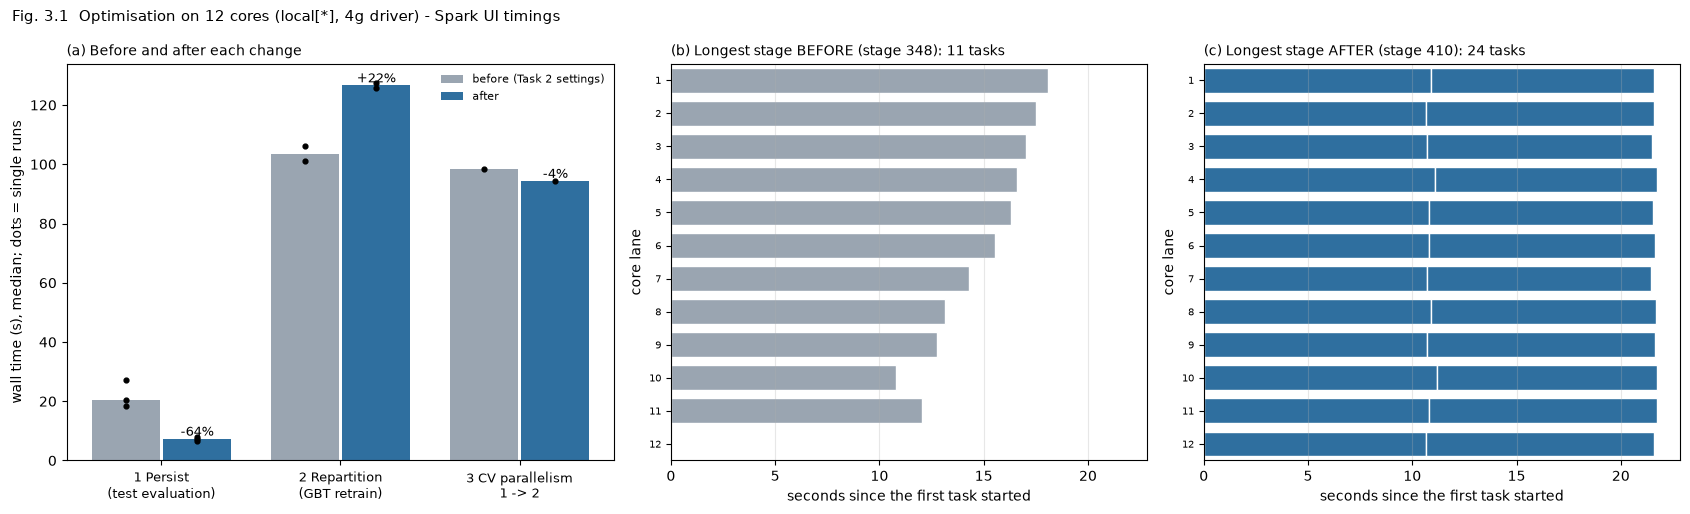

saved: task3/figures/task3_optimisation.png
saved: task3/results/task3_results.json [optimisation]
saved: results/task3.json [optimisation]


In [9]:
# ==============================================================================
# 3.1.6  Table 3.1, Fig. 3.1 and results/task3.json (optimisation section)
## AI: summary table, figure layout and JSON writer written with AI assistance
# ==============================================================================
import matplotlib.pyplot as plt


def pct_faster(c):
    return round(100 * (c["before_s"] - c["after_s"]) / c["before_s"], 1)


OPT_TABLE = pd.DataFrame([
    {"Change made": "Persist the scored test set",
     "Setting": "persist(MEMORY_AND_DISK), 4 columns",
     "Rationale": (f"{DIAG.get('full_scans', '?')} of {DIAG.get('jobs', '?')} metric jobs re-read {N_TEST:,} rows and "
                   f"re-ran the pipeline + {RECOMMENDED} (Table 3.1b); cache holds {STORAGE['four_columns_mb'][0]} MB "
                   f"vs {STORAGE['all_columns_mb'][0]} MB for all columns"),
     "Stage": f"test scan + score, repeated in {DIAG.get('full_scans', '?')} jobs",
     "Before (s)": round(C1["before_s"], 2), "After (s)": round(C1["after_s"], 2), "Faster (%)": pct_faster(C1)},
    {"Change made": "Repartition before caching",
     "Setting": f"{C2['partitions_before']} -> {TARGET_PARTITIONS} partitions (round-robin)",
     "Rationale": (f"{C2['partitions_before']} uneven partitions for {N_CORES} cores: longest task "
                   f"{P_B['max_over_median']}x the median on every pass; balanced tasks, 2 per core"),
     "Stage": (f"{est_cls.__name__} retrain, {P_B['pass_stages']} data passes of {P_B['tasks_per_pass']} -> "
               f"{P_A['tasks_per_pass']} tasks"),
     "Before (s)": round(C2["before_s"], 2), "After (s)": round(C2["after_s"], 2), "Faster (%)": pct_faster(C2)},
    {"Change made": "Fit CV combinations in parallel",
     "Setting": "CrossValidator parallelism 1 -> 2",
     "Rationale": (f"{C3['jobs']} short jobs left cores idle ({C3['core_use_before_pct']}% busy); 2 fits at a time "
                   f"-> {C3['core_use_after_pct']}% busy; 4 checked: {C3['checked_4_s']:.1f} s"),
     "Stage": f"CrossValidator.fit, LR 4 x {CV_FOLDS} folds on {N_TUNE:,} rows",
     "Before (s)": round(C3["before_s"], 2), "After (s)": round(C3["after_s"], 2), "Faster (%)": pct_faster(C3)},
])
show(OPT_TABLE, "Table 3.1  Spark UI interpretation and optimisation (median wall time, Task 2 settings as 'before')")
OPT_TABLE.to_csv(RES_DIR / "task3_optimisation.csv", index=False)

# ---- Fig. 3.1 ----
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.15, 1, 1]})
labels = ["1 Persist\n(test evaluation)", f"2 Repartition\n({est_cls.__name__[:3]} retrain)", "3 CV parallelism\n1 -> 2"]
runs = [(RUNS1["before"], RUNS1["after"]), (RUNS2["before"], RUNS2["after"]), ([C3["before_s"]], [C3["after_s"]])]
x = np.arange(3)
for i, (b, a) in enumerate(runs):
    ax1.bar(i - 0.2, statistics.median(b), 0.38, color="#9aa5b1", label="before (Task 2 settings)" if i == 0 else None)
    ax1.bar(i + 0.2, statistics.median(a), 0.38, color="#2f6f9f", label="after" if i == 0 else None)
    ax1.scatter([i - 0.2] * len(b), b, color="black", s=12, zorder=3)
    ax1.scatter([i + 0.2] * len(a), a, color="black", s=12, zorder=3)
    ax1.text(i + 0.2, statistics.median(a), f"{-OPT_TABLE.iloc[i]['Faster (%)']:+.0f}%", ha="center",
             va="bottom", fontsize=9)
ax1.set_xticks(x, labels, fontsize=9); ax1.set_ylabel("wall time (s), median; dots = single runs")
ax1.set_title("(a) Before and after each change", loc="left", fontsize=10); ax1.legend(fontsize=8, frameon=False)
for ax, key, title in ((ax2, "before", f"(b) Longest stage BEFORE (stage {STAGE_B}): {len(TL_B)} tasks"),
                       (ax3, "after", f"(c) Longest stage AFTER (stage {STAGE_A}): {len(TL_A)} tasks")):
    t = TIMELINE[key]
    lanes_end = []
    for _, r in t.iterrows():                                          # EXPLAIN: put each task on a free core lane
        lane = next((k for k, end in enumerate(lanes_end) if end <= r["start"] + 1e-3), None)
        if lane is None:
            lanes_end.append(0.0); lane = len(lanes_end) - 1
        lanes_end[lane] = r["start"] + r["dur"]
        ax.barh(lane, r["dur"], left=r["start"], height=0.75, color="#2f6f9f" if key == "after" else "#9aa5b1",
                edgecolor="white")
    ax.set_ylim(N_CORES - 0.5, -0.5); ax.set_yticks(range(N_CORES)); ax.set_yticklabels(range(1, N_CORES + 1), fontsize=7)
    ax.set_xlabel("seconds since the first task started"); ax.set_ylabel("core lane")
    ax.set_title(title, loc="left", fontsize=10)
xmax = max([(t["start"] + t["dur"]).max() for t in TIMELINE.values() if not t.empty] or [1])
for ax in (ax2, ax3):
    ax.set_xlim(0, xmax * 1.05); ax.grid(axis="x", alpha=0.3)
fig.suptitle(f"Fig. 3.1  Optimisation on {N_CORES} cores (local[*], {DRIVER_MEMORY} driver) - Spark UI timings",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_optimisation.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved:", rel(FIG_DIR / "task3_optimisation.png"))


# ---- results/task3.json: written section by section (3.2 and 3.3 add their own blocks later) ----
def save_task3(section, payload):
    header = {"task": 3, "notebook": NOTEBOOK, "quick_test": QUICK_TEST, "student": task1.get("student"),
              "pool_reference": task1.get("pool_reference"), "problem_type": "regression", "target_col": TARGET,
              "input_contract": ["results/task1.json#handoff", "results/task2.json#models"],
              "executor_config": EXECUTOR_CONFIG, "resources": RESOURCES,
              "spark_ui": {"application_id": sc.applicationId, "url": sc.uiWebUrl, "rest_api_read": UI_REACHABLE}}
    targets = [RES_DIR / "task3_results.json"] + ([] if QUICK_TEST else [ROOT / "results" / "task3.json"])
    for path in targets:
        data = json.loads(path.read_text()) if path.exists() else {}
        if data and data.get("notebook") != NOTEBOOK:
            print(f"NOT overwritten: {rel(path)} was written by another notebook"); continue
        data.update(header); data[section] = payload
        path.write_text(json.dumps(data, indent=2, default=str))
        print("saved:", rel(path), f"[{section}]")


save_task3("optimisation", {
    "method": "Task 2 settings as 'before'; one change at a time; before/after runs alternate; median wall time; "
              "every run is a named Spark job group; stage metrics read from the Spark UI REST API",
    "recommended_model": RECOMMENDED, "input_layout": INPUT_LAYOUT.to_dict("records"),
    "baseline": {"diagnosis": DIAG, "jobs": BASE_JOBS.to_dict("records"), "stages": BASE_STAGES.to_dict("records")},
    "changes": OPT_TABLE.to_dict("records"),
    "details": {"persist": C1, "repartition": C2, "cv_parallelism": C3},
    "measured_at": time.strftime("%Y-%m-%d %H:%M:%S"),
})

## 3.2 Stability analysis
**Question.** A deployed model receives readings from real weather stations, and some of those readings are slightly wrong. If its inputs are slightly wrong, how much does each model's forecast, and its error, change? A **stable** model gives almost the same forecast and almost the same error.

**What is perturbed.** Only the test data, as the answer sheet asks. The four saved Task 2 models are used as they are and not retrained.

| Perturbation | What changes | Why this size |
|---|---|---|
| **Sensor noise 10%** (main, used in Table 3.2) | Every measured temperature (TMAX, TMIN, TOBS, the two lags, the 7-day means, DTR) gets random noise with a standard deviation of 10% of that feature's training SD, about ±1.2 °C on TMAX. Rain, snow and snow depth get ±10% noise proportional to their value, so a dry day stays dry. | About the size of thermometer, siting and rounding errors at real stations |
| Sensor noise 5% | Same, at half the size | Does the damage double when the noise doubles? |
| Missing readings 10% | 10% of the measured readings are blanked out; the pipeline's median imputer fills them | Task 1 found about 14% of days missing in the raw data |
| TMAX +1 °C only (check) | Today's TMAX reading is raised by exactly 1 °C; nothing else changes | Shows how strongly each model leans on that one reading, which explains the ranking |

**Not perturbed:** the calendar features (`doy_sin`, `doy_cos`, `YEAR_f`) and the state, because these are never measured wrongly. A missing reading stays missing.

**Fair comparison**

- The noise for each station-day comes from a hash of its ID and date, so every model sees exactly the same perturbed rows, and the run gives the same numbers on any computer.
- The main perturbation is repeated with a second seed, to show that the result does not depend on one random draw.
- The scored test set is persisted once per perturbation and then reused for every metric: Change 1 from section 3.1.

**Measures (Δ = perturbed − clean)**

- **Δ RMSE** and **Δ R²**: how much the error grows.
- **How far the forecast itself moves**: the mean |Δŷ|, the 95th percentile, and the share of days that move by more than 1 °C.
- **Rank 1** = the smallest Δ RMSE (the most stable model).

*Why not retrain on perturbed training data?* Retraining all four models cost about 85 minutes in Task 2. Perturbing the test inputs measures the property that matters for a model already in use: how sensitive its output is to its inputs.

In [10]:
# ==============================================================================
# 3.2.1  Perturbed copies of the test set, and all four models scored once per copy
# REF: Week 5 lecture "Model Evaluation / stability" (perturb inputs, compare metrics);
#      Task 2 notebook cell 1.7 (hash of ID + date: the same number for a row on every computer);
#      section 3.1 Change 1 (score once, persist, reuse)
## AI: hash-based noise, perturbation set-up and the wide scoring table written with AI assistance
# ==============================================================================
import matplotlib.pyplot as plt

MODELS3 = {n: PipelineModel.load(spark_path(p)) for n, p in MODEL_PATHS.items()}     # the four Task 2 pipelines
NUM = list(imp_m.getInputCols())                                                    # the 14 numeric features
CALENDAR = {"doy_sin", "doy_cos", "YEAR_f"}                                         # never measured wrongly
MEASURED = [c for c in NUM if c not in CALENDAR]
AMOUNTS = {"PRCP", "SNOW", "SNWD"}                                                  # proportional noise: dry stays dry
TRAIN_SD = dict(zip(NUM, (float(x) for x in scaler_m.std.toArray()[:len(NUM)])))   # Task 1 scaler = training SD
KEY = ["ID", "date"]


def _uniform(seed, i, part):
    """A number in (0, 1) from a hash of the row: the same value for a station-day on every computer."""
    h = F.xxhash64(F.col("ID"), F.col("date"), F.lit(seed), F.lit(i), F.lit(part))
    return (F.pmod(h, F.lit(2**31 - 1)) + 1) / F.lit(float(2**31))


def _gauss(seed, i):
    """Standard normal noise (Box-Muller) from two hashed uniforms."""
    return F.sqrt(-2.0 * F.log(_uniform(seed, i, 1))) * F.cos(2 * math.pi * _uniform(seed, i, 2))


def with_noise(df, k, seed):
    for i, c in enumerate(MEASURED):
        z = _gauss(seed, i)
        noisy = (F.greatest(F.col(c) * (1 + k * z), F.lit(0.0)) if c in AMOUNTS
                 else F.col(c) + F.lit(k * TRAIN_SD[c]) * z)
        df = df.withColumn(c, F.when(F.col(c).isNull(), F.lit(None).cast("double")).otherwise(noisy))
    return df


def with_missing(df, frac, seed):
    for i, c in enumerate(MEASURED):
        df = df.withColumn(c, F.when(_uniform(seed, i, 3) < frac, F.lit(None).cast("double")).otherwise(F.col(c)))
    return df


PERTURBATIONS = {                                       # key: (label for the tables, function)
    "clean":       ("No perturbation", lambda d: d),
    "noise10_s42": ("Sensor noise 10% of SD (seed 42)", lambda d: with_noise(d, 0.10, 42)),
    "noise10_s7":  ("Sensor noise 10% of SD (seed 7)", lambda d: with_noise(d, 0.10, 7)),
    "noise5":      ("Sensor noise 5% of SD", lambda d: with_noise(d, 0.05, 42)),
    "missing10":   ("10% of readings missing", lambda d: with_missing(d, 0.10, 42)),
    "tmax_plus1":  ("TMAX +1 deg C only (check)", lambda d: d.withColumn("TMAX", F.col("TMAX") + 1.0)),
}
MAIN = "noise10_s42"
test_in = test_raw.select(*KEY, TARGET, *idx_m.getInputCols(), *NUM)


def score_all(df):
    """One table per perturbation: label + the four models' predictions, persisted once (Change 1)."""
    base = df.persist(StorageLevel.MEMORY_AND_DISK); base.count()
    wide = base.select(*KEY, TARGET)
    for n, m in MODELS3.items():
        wide = wide.join(m.transform(base).select(*KEY, F.col("prediction").alias(f"p_{n}")), KEY)
    wide = wide.persist(StorageLevel.MEMORY_AND_DISK); wide.count()
    base.unpersist()
    return wide


SCORED, T32 = {}, {}
for key, (label, fn) in PERTURBATIONS.items():
    t0 = time.perf_counter()
    SCORED[key] = score_all(fn(test_in))
    T32[key] = round(time.perf_counter() - t0, 1)
    print(f"  {label:<36} scored by {len(MODELS3)} models in {T32[key]:5.1f} s", flush=True)

  No perturbation                      scored by 4 models in  41.9 s
  Sensor noise 10% of SD (seed 42)     scored by 4 models in  37.6 s
  Sensor noise 10% of SD (seed 7)      scored by 4 models in  37.8 s
  Sensor noise 5% of SD                scored by 4 models in  39.3 s
  10% of readings missing              scored by 4 models in  38.3 s
  TMAX +1 deg C only (check)           scored by 4 models in  34.5 s


In [11]:
# ==============================================================================
# 3.2.2  Table 3.2 - delta RMSE, delta R2 and how far each forecast moves, for all four models
# REF: Day06_Regression_LiveCoding_Solutions_Colab > cell-9 [Day 6]: RMSE / R2 definitions (same as Table 2.3)
## AI: one-pass stability aggregation, rank rule and the Linear Regression cross-check written with AI assistance
# ==============================================================================
def stability(key):
    """Clean vs perturbed for every model in one distributed pass over the 433,788 test rows."""
    pert = SCORED[key].select(*KEY, *[F.col(f"p_{n}").alias(f"q_{n}") for n in MODELS3])
    both = SCORED["clean"].join(pert, KEY)
    y = F.col(TARGET)
    aggs = [F.var_pop(y).alias("var_y"), F.count(F.lit(1)).alias("n")]
    for n in MODELS3:
        e0, e1, d = y - F.col(f"p_{n}"), y - F.col(f"q_{n}"), F.col(f"q_{n}") - F.col(f"p_{n}")
        aggs += [F.avg(e0 * e0).alias(f"{n}|mse0"), F.avg(e1 * e1).alias(f"{n}|mse1"),
                 F.avg(F.abs(d)).alias(f"{n}|mad"), F.stddev_pop(d).alias(f"{n}|sd"), F.avg(d).alias(f"{n}|mean"),
                 F.percentile_approx(F.abs(d), 0.95, 10000).alias(f"{n}|p95"),
                 F.avg((F.abs(d) > 1).cast("double")).alias(f"{n}|gt1")]
    a = both.select(*aggs).first()
    rows = []
    for n in MODELS3:
        rmse0, rmse1 = math.sqrt(a[f"{n}|mse0"]), math.sqrt(a[f"{n}|mse1"])
        r2_0, r2_1 = 1 - a[f"{n}|mse0"] / a["var_y"], 1 - a[f"{n}|mse1"] / a["var_y"]
        rows.append({"Model": n, "Perturbation": PERTURBATIONS[key][0], "Clean RMSE": round(rmse0, 4),
                     "Perturbed RMSE": round(rmse1, 4), "Delta RMSE": round(rmse1 - rmse0, 4),
                     "Delta RMSE (%)": round(100 * (rmse1 - rmse0) / rmse0, 2),
                     "Clean R2": round(r2_0, 4), "Perturbed R2": round(r2_1, 4), "Delta R2": round(r2_1 - r2_0, 4),
                     "Mean |forecast change| (deg C)": round(a[f"{n}|mad"], 3),
                     "Mean forecast change (deg C)": round(a[f"{n}|mean"], 3),
                     "SD of forecast change": round(a[f"{n}|sd"], 3),
                     "95th pct |forecast change|": round(float(a[f"{n}|p95"]), 3),
                     "Days moved > 1 deg C (%)": round(100 * a[f"{n}|gt1"], 1)})
    return pd.DataFrame(rows)


STAB = pd.concat([stability(k) for k in PERTURBATIONS if k != "clean"], ignore_index=True)

# the clean scores must reproduce Task 2's Table 2.3 (same models, same test rows)
for n in MODELS3:
    t2 = task2["models"][n]["test_metrics"]["RMSE"]
    mine = STAB.loc[STAB["Model"] == n, "Clean RMSE"].iloc[0]
    assert abs(mine - t2) < 1e-3, f"{n}: clean RMSE {mine} differs from Table 2.3 ({t2:.4f})"
print("clean RMSE of every model matches Table 2.3 (results/task2.json)")

main = STAB[STAB["Perturbation"] == PERTURBATIONS[MAIN][0]].copy()
main["Rank"] = main["Delta RMSE"].rank(method="min").astype(int)            # 1 = most stable
main = main.sort_values("Rank")
TABLE_32 = main[["Model", "Perturbation", "Delta RMSE", "Delta R2", "Rank"]].rename(
    columns={"Delta RMSE": "Δ RMSE (°C)", "Delta R2": "Δ R²", "Perturbation": "Perturbation applied"})
show(TABLE_32, "Table 3.2  Stability under sensor noise (answer-sheet columns; rank 1 = most stable)")
show(main[["Model", "Clean RMSE", "Perturbed RMSE", "Delta RMSE (%)", "Clean R2", "Perturbed R2",
           "Mean |forecast change| (deg C)", "95th pct |forecast change|", "Days moved > 1 deg C (%)"]],
     "Table 3.2a  The same run in detail: how far each model's forecast moves")
CHECK = PERTURBATIONS["tmax_plus1"][0]
show(STAB[STAB["Perturbation"] != CHECK][["Model", "Perturbation", "Delta RMSE", "Delta RMSE (%)", "Delta R2",
                                          "Mean |forecast change| (deg C)", "Days moved > 1 deg C (%)"]],
     "Table 3.2b  Every perturbation (dose-response, second seed, missing readings)")


def leans_on_tmax(n):
    """Share of the model that depends on today's TMAX reading (trees: split importance; LR: weight share)."""
    last = MODELS3[n].stages[-1]
    if hasattr(last, "featureImportances"):
        return round(float(last.featureImportances.toArray()[NUM.index("TMAX")]), 3)
    if n == "LinearRegression":
        w = np.abs(last.coefficients.toArray()[[NUM.index(c) for c in MEASURED]])
        return round(float(w[MEASURED.index("TMAX")] / w.sum()), 3)
    return None                                         # FM: most of its output comes from pairwise products


SENS = STAB[STAB["Perturbation"] == CHECK][["Model", "Mean forecast change (deg C)"]].rename(
    columns={"Mean forecast change (deg C)": "Forecast change when TMAX is +1 deg C"})
SENS["TMAX share of importance / weight"] = [leans_on_tmax(n) for n in SENS["Model"]]
SENS = SENS.merge(main[["Model", "Rank"]], on="Model").sort_values("Rank")
show(SENS, "Table 3.2c  Why: how strongly each model leans on one reading (TMAX)")
TABLE_32.to_csv(RES_DIR / "task3_stability.csv", index=False)
STAB.to_csv(RES_DIR / "task3_stability_all.csv", index=False)

# ---- does the answer depend on the random draw? (seed 42 vs seed 7) ----
seed_cmp = STAB.pivot(index="Model", columns="Perturbation", values="Delta RMSE")
s42, s7 = PERTURBATIONS["noise10_s42"][0], PERTURBATIONS["noise10_s7"][0]
SEED_SPREAD = float((seed_cmp[s42] - seed_cmp[s7]).abs().max())
same_order = list(seed_cmp[s42].sort_values().index) == list(seed_cmp[s7].sort_values().index)
print(f"second seed: largest change in any model's delta RMSE {SEED_SPREAD:.4f} deg C; "
      f"stability ranking {'unchanged' if same_order else 'CHANGED'}")

# ---- Linear Regression cross-check: for a linear model the forecast change can be worked out exactly ----
LR_CHECK = None
if "LinearRegression" in MODELS3:
    lr_pipe = MODELS3["LinearRegression"]
    beta = lr_pipe.stages[-1].coefficients.toArray()[:len(NUM)]
    s_lr = lr_pipe.stages[4].std.toArray()[:len(NUM)]
    stats = test_raw.select(*[F.avg(F.col(c).isNotNull().cast("double")).alias(f"nn_{c}") for c in MEASURED],
                            *[F.avg(F.coalesce(F.col(c), F.lit(0.0)) ** 2).alias(f"sq_{c}") for c in AMOUNTS]).first()
    var = 0.0
    for i, c in enumerate(NUM):
        if c not in MEASURED:
            continue
        if c in AMOUNTS:                                    # delta x = x * k * z   -> (beta/s)^2 * k^2 * E[x^2]
            var += (beta[i] / s_lr[i]) ** 2 * 0.10 ** 2 * stats[f"sq_{c}"]
        else:                                               # delta x = k * SD * z  -> (beta/s * k * SD)^2 * P(present)
            var += (beta[i] / s_lr[i] * 0.10 * TRAIN_SD[c]) ** 2 * stats[f"nn_{c}"]
    measured_sd = float(main.loc[main["Model"] == "LinearRegression", "SD of forecast change"].iloc[0])
    LR_CHECK = {"expected_sd": round(math.sqrt(var), 3), "measured_sd": round(measured_sd, 3)}
    print(f"Linear Regression: the weights predict the forecast should move with SD {LR_CHECK['expected_sd']} deg C "
          f"under 10% noise; measured {LR_CHECK['measured_sd']} deg C")

most, least = main.iloc[0], main.iloc[-1]
rec = main[main["Model"] == RECOMMENDED].iloc[0]
print(f"\nMost stable : {most['Model']} (delta RMSE {most['Delta RMSE']:+.4f} deg C, delta R2 {most['Delta R2']:+.4f}, "
      f"forecast moves {most['Mean |forecast change| (deg C)']} deg C on average)")
print(f"Least stable: {least['Model']} (delta RMSE {least['Delta RMSE']:+.4f} deg C, delta R2 {least['Delta R2']:+.4f}, "
      f"forecast moves {least['Mean |forecast change| (deg C)']} deg C on average)")
print(f"Recommended in Task 2: {RECOMMENDED} - stability rank {int(rec['Rank'])} of {len(main)}; "
      f"perturbed RMSE {rec['Perturbed RMSE']} vs best perturbed RMSE {main['Perturbed RMSE'].min()} "
      f"({main.loc[main['Perturbed RMSE'].idxmin(), 'Model']})")

clean RMSE of every model matches Table 2.3 (results/task2.json)
Table 3.2  Stability under sensor noise (answer-sheet columns; rank 1 = most stable)


,Model,Perturbation applied,Δ RMSE (°C),Δ R²,Rank
2,FMRegressor,Sensor noise 10% of SD (seed 42),0.0288,-0.0017,1
1,RandomForestRegressor,Sensor noise 10% of SD (seed 42),0.0724,-0.0039,2
0,LinearRegression,Sensor noise 10% of SD (seed 42),0.0773,-0.0044,3
3,GBTRegressor,Sensor noise 10% of SD (seed 42),0.0856,-0.0047,4


Table 3.2a  The same run in detail: how far each model's forecast moves


,Model,Clean RMSE,Perturbed RMSE,Delta RMSE (%),Clean R2,Perturbed R2,Mean |forecast change| (deg C),95th pct |forecast change|,Days moved > 1 deg C (%)
2,FMRegressor,4.0822,4.1110,0.71,0.8829,0.8813,0.389,0.961,4.2
1,RandomForestRegressor,3.7924,3.8648,1.91,0.8990,0.8951,0.644,1.753,23.0
0,LinearRegression,3.9740,4.0513,1.94,0.8891,0.8847,0.636,1.562,21.0
3,GBTRegressor,3.8529,3.9385,2.22,0.8957,0.8910,0.798,2.857,28.6


Table 3.2b  Every perturbation (dose-response, second seed, missing readings)


,Model,Perturbation,Delta RMSE,Delta RMSE (%),Delta R2,Mean |forecast change| (deg C),Days moved > 1 deg C (%)
0,LinearRegression,Sensor noise 10% of SD (seed 42),0.0773,1.94,-0.0044,0.636,21.0
1,RandomForestRegressor,Sensor noise 10% of SD (seed 42),0.0724,1.91,-0.0039,0.644,23.0
2,FMRegressor,Sensor noise 10% of SD (seed 42),0.0288,0.71,-0.0017,0.389,4.2
3,GBTRegressor,Sensor noise 10% of SD (seed 42),0.0856,2.22,-0.0047,0.798,28.6
4,LinearRegression,Sensor noise 10% of SD (seed 7),0.0789,1.99,-0.0044,0.639,21.2
5,RandomForestRegressor,Sensor noise 10% of SD (seed 7),0.0730,1.93,-0.0039,0.647,23.2
6,FMRegressor,Sensor noise 10% of SD (seed 7),0.0300,0.74,-0.0017,0.390,4.2
7,GBTRegressor,Sensor noise 10% of SD (seed 7),0.0878,2.28,-0.0048,0.798,28.5
8,LinearRegression,Sensor noise 5% of SD,0.0189,0.48,-0.0011,0.318,1.2
9,RandomForestRegressor,Sensor noise 5% of SD,0.0202,0.53,-0.0011,0.359,8.1


Table 3.2c  Why: how strongly each model leans on one reading (TMAX)


,Model,Forecast change when TMAX is +1 deg C,TMAX share of importance / weight,Rank
2,FMRegressor,0.212,NaN,1
1,RandomForestRegressor,0.554,0.415,2
0,LinearRegression,0.593,0.456,3
3,GBTRegressor,0.651,0.796,4


second seed: largest change in any model's delta RMSE 0.0022 deg C; stability ranking unchanged
Linear Regression: the weights predict the forecast should move with SD 0.8 deg C under 10% noise; measured 0.798 deg C

Most stable : FMRegressor (delta RMSE +0.0288 deg C, delta R2 -0.0017, forecast moves 0.389 deg C on average)
Least stable: GBTRegressor (delta RMSE +0.0856 deg C, delta R2 -0.0047, forecast moves 0.798 deg C on average)
Recommended in Task 2: GBTRegressor - stability rank 4 of 4; perturbed RMSE 3.9385 vs best perturbed RMSE 3.8648 (RandomForestRegressor)


### 3.2.3 Why the models differ: how each algorithm turns an input error into a forecast error
Read this with Tables 3.2a and 3.2c. Each model reacts to a wrong reading in a different way:

| Model | How a wrong reading reaches the forecast |
|---|---|
| **Linear Regression** | ŷ = Σ wᵢxᵢ, so an error εᵢ in one input moves the forecast by exactly wᵢεᵢ. Every input error passes straight through. The cell above checks this: the model's own weights predict how far its forecasts should move, and the measured spread matches. A missing reading is worse: the imputer puts in the training median, and a linear model carries the whole gap (for example a 35 °C day read as about 20 °C) into the forecast. |
| **Random Forest** | An average of 50 deep trees. Each split may only choose from a random third of the features, so the trees spread their splits over TMAX, its 7-day mean, the lags and TMIN. Noise in one reading moves only the trees that split on it, and only where it crosses a split point. The other trees, and the noise in the other readings, partly cancel it out. Every tree's answer is an average of training days, so one wrong value cannot push the forecast past what was seen in training. |
| **GBT** | A sum of 60 shallow trees. Each tree corrects the previous ones, so most of them split on the strongest single input, today's TMAX (see the TMAX share in Table 3.2c). A wrong TMAX crosses the split points of many trees at once, and their steps **add up** instead of averaging out. That gives the largest moves in Table 3.2a. |
| **Factorisation machine** | It was trained with a small step size (0.01, because larger steps diverged in Task 2) for at most 100 iterations. Its weights stayed small, so it reacts little to any single reading. Its effect per degree of TMAX is the smallest in Table 3.2c. This is **the same caution that made it the least accurate model** in Table 2.3. It is stable because it under-fits, not because it reads the weather better. |

**Size of the effect.** Halving the noise roughly quarters Δ RMSE (Table 3.2b). This is expected: the forecast error and the noise-induced change add up as squares, RMSE² ≈ RMSE₀² + Var(Δŷ).

**Trust in deployment** is about the perturbed RMSE, not only Δ. A model that barely moves but starts with a large error is still worse than one that moves a little from a smaller error. The last lines of cell 3.2.2 compare the recommended model with the best perturbed RMSE.

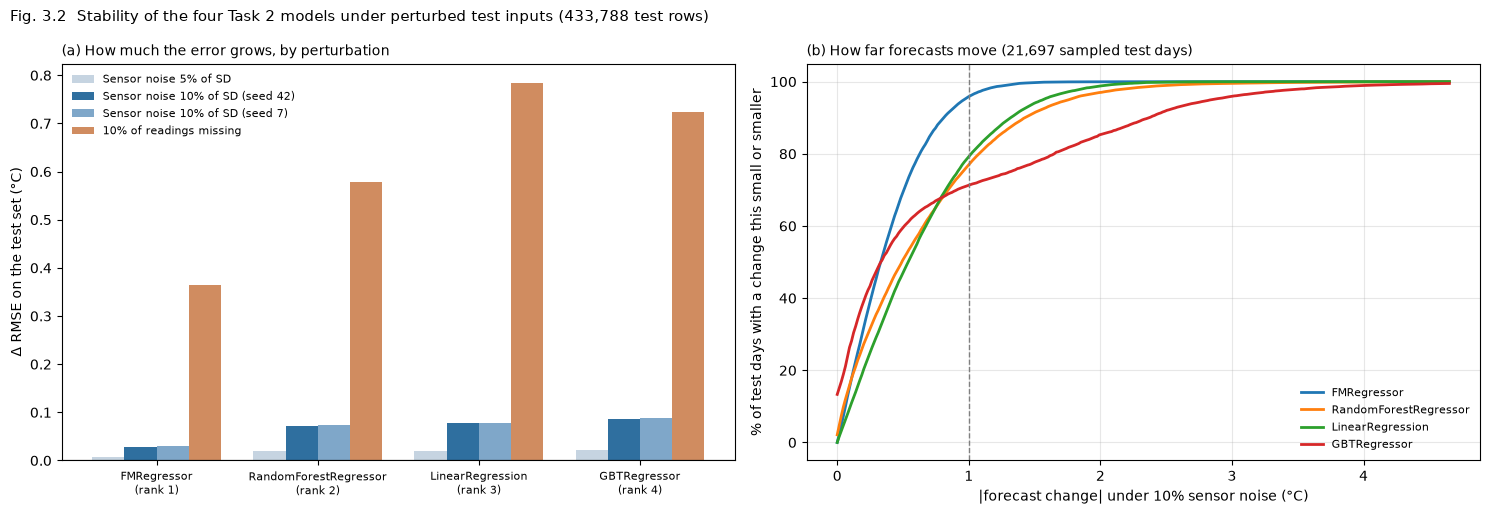

saved: task3/figures/task3_stability.png
saved: task3/results/task3_results.json [stability]
saved: results/task3.json [stability]


In [12]:
# ==============================================================================
# 3.2.4  Fig. 3.2 and results/task3.json (stability section)
## AI: figure layout and JSON block written with AI assistance
# ==============================================================================
if "save_task3" not in globals():                      # section 3.1 was not run in this session
    def save_task3(section, payload):
        header = {"task": 3, "notebook": NOTEBOOK, "quick_test": QUICK_TEST, "student": task1.get("student"),
                  "pool_reference": task1.get("pool_reference"), "problem_type": "regression", "target_col": TARGET,
                  "input_contract": ["results/task1.json#handoff", "results/task2.json#models"],
                  "executor_config": EXECUTOR_CONFIG}
        targets = [RES_DIR / "task3_results.json"] + ([] if QUICK_TEST else [ROOT / "results" / "task3.json"])
        for path in targets:
            data = json.loads(path.read_text()) if path.exists() else {}
            if data and data.get("notebook") != NOTEBOOK:
                print(f"NOT overwritten: {rel(path)} was written by another notebook"); continue
            data.update(header); data[section] = payload
            path.write_text(json.dumps(data, indent=2, default=str))
            print("saved:", rel(path), f"[{section}]")

order = list(main["Model"])                                            # most -> least stable
labels = [PERTURBATIONS[k][0] for k in ("noise5", "noise10_s42", "noise10_s7", "missing10")]
colours = ["#c6d4e1", "#2f6f9f", "#7fa7c9", "#d08c60"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))
w = 0.2
for j, (lab, col) in enumerate(zip(labels, colours)):
    vals = [STAB[(STAB["Model"] == m) & (STAB["Perturbation"] == lab)]["Delta RMSE"].iloc[0] for m in order]
    ax1.bar(np.arange(len(order)) + (j - 1.5) * w, vals, w, label=lab, color=col)
ax1.set_xticks(range(len(order)), [f"{m}\n(rank {int(r)})" for m, r in zip(order, main["Rank"])], fontsize=8)
ax1.axhline(0, color="black", lw=0.8)
ax1.set_ylabel("Δ RMSE on the test set (°C)"); ax1.legend(fontsize=8, frameon=False)
ax1.set_title("(a) How much the error grows, by perturbation", loc="left", fontsize=10)

samp = (SCORED["clean"].join(SCORED[MAIN].select(*KEY, *[F.col(f"p_{n}").alias(f"q_{n}") for n in MODELS3]), KEY)
        .filter(F.abs(F.xxhash64(*[F.col(k) for k in KEY])) % 100 < 5)
        .select(*[F.abs(F.col(f"q_{n}") - F.col(f"p_{n}")).alias(n) for n in MODELS3]).toPandas())
xs = np.linspace(0, max(3.0, float(samp.quantile(0.995).max())), 300)
for n in order:
    ax2.plot(xs, [(samp[n] <= x).mean() * 100 for x in xs], lw=2, label=n)
ax2.axvline(1.0, color="grey", ls="--", lw=1)
ax2.set_xlabel("|forecast change| under 10% sensor noise (°C)"); ax2.set_ylabel("% of test days with a change this small or smaller")
ax2.set_title(f"(b) How far forecasts move ({len(samp):,} sampled test days)", loc="left", fontsize=10)
ax2.legend(fontsize=8, frameon=False); ax2.grid(alpha=0.3)
fig.suptitle("Fig. 3.2  Stability of the four Task 2 models under perturbed test inputs (433,788 test rows)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_stability.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved:", rel(FIG_DIR / "task3_stability.png"))

save_task3("stability", {
    "method": "test inputs perturbed (hash-based noise, identical rows for every model); models not retrained; "
              "delta = perturbed - clean on all test rows; rank 1 = smallest delta RMSE",
    "main_perturbation": PERTURBATIONS[MAIN][0], "measured_features": MEASURED,
    "noise_sd_per_feature_deg_c_at_10pct": {c: round(0.10 * TRAIN_SD[c], 3) for c in MEASURED if c not in AMOUNTS},
    "table_3_2": TABLE_32.to_dict("records"), "detail": main.to_dict("records"), "all": STAB.to_dict("records"),
    "most_stable": most["Model"], "least_stable": least["Model"],
    "recommended_model": RECOMMENDED, "recommended_rank": int(rec["Rank"]),
    "seed_check": {"max_abs_delta_rmse_difference": round(SEED_SPREAD, 4), "ranking_unchanged": same_order},
    "linear_regression_check": LR_CHECK, "scoring_time_s": T32,
})
for df_ in SCORED.values():
    df_.unpersist()

## 3.3 Explainability and fairness
### 3.3.1 SHAP values for the recommended model
- **Self-check:** for every explained day, base value + Σ SHAP must equal Spark's own prediction. The cell stops if it does not.
- **Days explained:** the same 1.2% of test days as Fig. 2.1 and EP2 (about 5,000 days, chosen by a hash of ID + date).
- **Node weights:** taken from 2% of the training rows (about 51,000).
- **State:** the 40 one-hot state columns are added together into one feature, `state_code`, so the state competes as one input.

In [13]:
# ==============================================================================
# 3.3.1  Exact TreeSHAP from the trees Spark saved (no extra package needed)
# REF: Week 5 lecture "ML Explainability (XAI)" (SHAP values, global importance = mean |SHAP|);
#      Lundberg, Erion & Lee (2020) Nature Machine Intelligence 2, 56-67: path-dependent TreeSHAP;
#      Spark ML API: GBTRegressionModel.trees / treeWeights / toDebugString
## AI: tree parser, vectorised Shapley formula and the additivity check written with AI assistance
# ==============================================================================
import re, itertools
import matplotlib.pyplot as plt
from pyspark.ml.functions import vector_to_array

_IF = re.compile(r"If \(feature (\d+) (<=|in) (.+)\)\s*$")
_ELSE = re.compile(r"Else \(feature (\d+) (>|not in) (.+)\)\s*$")
_LEAF = re.compile(r"Predict: (\S+)\s*$")


def parse_tree(debug_string):
    """One Spark tree (toDebugString) -> nested dicts; thresholds are printed at full precision."""
    lines = [l.strip() for l in debug_string.splitlines()[1:] if l.strip()]
    pos = 0

    def node():
        nonlocal pos
        line = lines[pos]; pos += 1
        m = _LEAF.match(line)
        if m:
            return {"leaf": float(m.group(1))}
        m = _IF.match(line)
        feat, op, val = int(m.group(1)), m.group(2), m.group(3)
        test = ("le", float(val)) if op == "<=" else ("in", {float(x) for x in val.strip("{}").split(",") if x})
        left = node()
        assert _ELSE.match(lines[pos]), f"unexpected tree line: {lines[pos]}"
        pos += 1
        return {"feature": feat, "test": test, "left": left, "right": node()}

    return node()


def goes_left(test, x):
    return x <= test[1] if test[0] == "le" else np.isin(x, list(test[1]))


def add_cover(tree, X):
    """How many background (training) rows reach each node: the weights TreeSHAP uses for a hidden feature."""
    def walk(n, idx):
        n["cover"] = float(len(idx))
        if "leaf" not in n:
            left = goes_left(n["test"], X[idx, n["feature"]])
            walk(n["left"], idx[left]); walk(n["right"], idx[~left])
    walk(tree, np.arange(X.shape[0]))


def leaf_paths(tree):
    out = []

    def walk(n, path):
        if "leaf" in n:
            out.append((n["leaf"], path)); return
        for child, left in ((n["left"], True), (n["right"], False)):
            share = child["cover"] / n["cover"] if n["cover"] > 0 else 0.5
            walk(child, path + [(n["feature"], n["test"], left, share)])
    walk(tree, [])
    return out


def shapley_table(v, z):
    """For one leaf: SHAP share of each path feature for every pattern of 'row follows this feature's splits'."""
    u, fact = len(z), [math.factorial(i) for i in range(len(z) + 1)]
    table = np.zeros((2 ** u, u))
    for p in range(2 ** u):
        o = [(p >> k) & 1 for k in range(u)]
        for i in range(u):
            others = [k for k in range(u) if k != i]
            total = 0.0
            for r in range(len(others) + 1):
                for S in itertools.combinations(others, r):
                    total += fact[r] * fact[u - r - 1] / fact[u] * math.prod(o[k] if k in S else z[k] for k in others)
            table[p, i] = v * (o[i] - z[i]) * total
    return table


def tree_shap(tree, X):
    phi, expected = np.zeros(X.shape), 0.0
    for v, path in leaf_paths(tree):
        feats = list(dict.fromkeys(f for f, *_ in path))
        z = [math.prod(s for f, _, _, s in path if f == j) for j in feats]
        expected += v * math.prod(z)
        pattern = np.zeros(X.shape[0], dtype=np.int64)
        for k, j in enumerate(feats):
            ok = np.ones(X.shape[0], dtype=bool)
            for f, test, left, _ in path:
                if f == j:
                    gl = goes_left(test, X[:, j]); ok &= gl if left else ~gl
            pattern |= ok.astype(np.int64) << k
        phi[:, feats] += shapley_table(v, z)[pattern]
    return phi, expected


def ensemble_shap(model, X_explain, X_background):
    """GBT prediction = sum of tree predictions x tree weights, so the SHAP values add up the same way."""
    phi, base = np.zeros(X_explain.shape), 0.0
    for t, w in zip(model.trees, model.treeWeights):
        tree = parse_tree(t.toDebugString)
        add_cover(tree, X_background)
        p, e = tree_shap(tree, X_explain)
        phi += w * p; base += w * e
    return phi, base


# ---- the model, the days to explain and the background rows ----
EXPLAINED = RECOMMENDED if RECOMMENDED in ("GBTRegressor", "RandomForestRegressor") else "GBTRegressor"
shap_pipe = PipelineModel.load(spark_path(MODEL_PATHS[EXPLAINED]))
tree_model = shap_pipe.stages[-1]
hash1000 = F.abs(F.xxhash64("ID", "date")) % 1000
ex_pd = (shap_pipe.transform(test_raw.filter(hash1000 < 12))
         .select("ID", "date", "state_code", TARGET, "prediction", vector_to_array(FEATURES_COL).alias("x")).toPandas())
bg_pd = shap_pipe.transform(train_raw.filter(hash1000 < 20)).select(vector_to_array(FEATURES_COL).alias("x")).toPandas()
X_EX, X_BG = np.array(ex_pd["x"].tolist()), np.array(bg_pd["x"].tolist())

t0 = time.perf_counter()
PHI, BASE = ensemble_shap(tree_model, X_EX, X_BG)
SHAP_S = round(time.perf_counter() - t0, 1)
ADDITIVITY = float(np.abs(BASE + PHI.sum(axis=1) - ex_pd["prediction"].to_numpy()).max())
assert ADDITIVITY < 1e-6, f"SHAP values do not add up to Spark's predictions (max error {ADDITIVITY})"
print(f"{EXPLAINED}: SHAP for {len(X_EX):,} test days x {X_EX.shape[1]} features in {SHAP_S} s "
      f"(node weights from {len(X_BG):,} training rows)")
print(f"base value {BASE:.3f} deg C; additivity check: base + sum(SHAP) = Spark prediction, max error {ADDITIVITY:.1e} deg C")

GBTRegressor: SHAP for 5,143 test days x 54 features in 10.7 s (node weights from 51,053 training rows)
base value 17.219 deg C; additivity check: base + sum(SHAP) = Spark prediction, max error 5.0e-14 deg C


Table 3.3a  GBTRegressor: features ranked by mean |SHAP| on 5,143 test days


,Rank,Feature,Mean |SHAP| (deg C),Spark split importance,Share of total |SHAP| (%)
0,1,TMAX,7.9205,0.7962,66.3
1,2,TMAX_roll7,0.8116,0.0272,6.8
2,3,doy_cos,0.7587,0.0301,6.3
3,4,TOBS,0.7083,0.0420,5.9
4,5,PRCP,0.6268,0.0303,5.2
5,6,TMAX_lag1,0.2577,0.0070,2.2
6,7,state_code,0.2321,0.0176,1.9
7,8,DTR,0.2115,0.0328,1.8
8,9,YEAR_f,0.1075,0.0012,0.9
9,10,SNOW,0.0951,0.0035,0.8


Top five features: 1. TMAX, 2. TMAX_roll7, 3. doy_cos, 4. TOBS, 5. PRCP


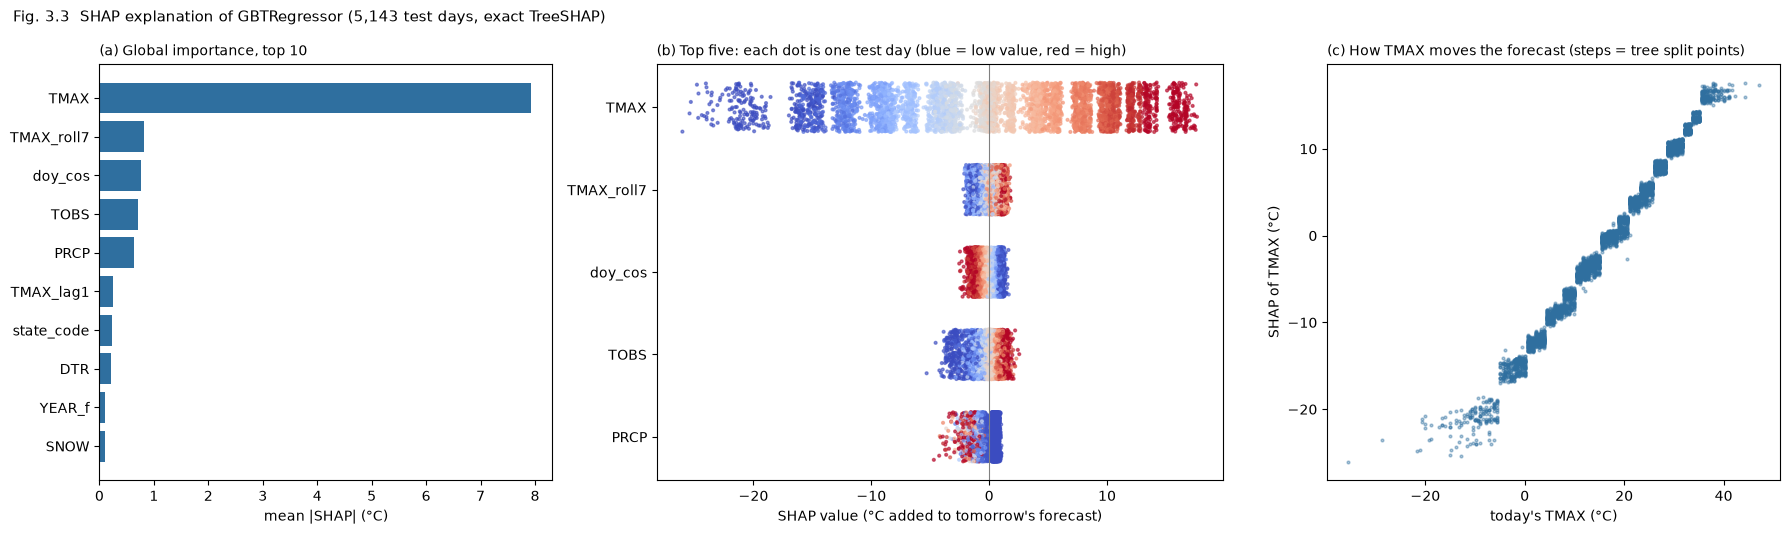

saved: task3/figures/task3_shap.png


In [14]:
# ==============================================================================
# 3.3.2  Top features: mean |SHAP| (state one-hots grouped), with Spark's own importance for comparison
## AI: grouping, ranking table and beeswarm/dependence plots written with AI assistance
# ==============================================================================
NUM = list(imp_m.getInputCols())                                     # the 14 numeric features
N_NUM = len(NUM)
STATE_COLS = list(range(N_NUM, X_EX.shape[1]))                      # the one-hot state block
SHAP_FEAT = {c: PHI[:, i] for i, c in enumerate(NUM)}
SHAP_FEAT["state_code"] = PHI[:, STATE_COLS].sum(axis=1)             # EXPLAIN: SHAP values add, so a group = their sum
spark_imp = tree_model.featureImportances.toArray()
SPARK_IMP = {c: float(spark_imp[i]) for i, c in enumerate(NUM)}
SPARK_IMP["state_code"] = float(spark_imp[STATE_COLS].sum())
std_all = t1_prep.stages[-1].std.toArray()

SHAP_TABLE = (pd.DataFrame({"Feature": list(SHAP_FEAT),
                            "Mean |SHAP| (deg C)": [float(np.abs(v).mean()) for v in SHAP_FEAT.values()],
                            "Spark split importance": [SPARK_IMP[c] for c in SHAP_FEAT]})
              .sort_values("Mean |SHAP| (deg C)", ascending=False).reset_index(drop=True))
SHAP_TABLE.insert(0, "Rank", range(1, len(SHAP_TABLE) + 1))
SHAP_TABLE["Share of total |SHAP| (%)"] = (100 * SHAP_TABLE["Mean |SHAP| (deg C)"]
                                            / SHAP_TABLE["Mean |SHAP| (deg C)"].sum()).round(1)
SHAP_TABLE = SHAP_TABLE.round(4)
TOP5 = list(SHAP_TABLE["Feature"].head(5))
show(SHAP_TABLE.head(10), f"Table 3.3a  {EXPLAINED}: features ranked by mean |SHAP| on {len(X_EX):,} test days")
SHAP_TABLE.to_csv(RES_DIR / "task3_shap_importance.csv", index=False)
print("Top five features:", ", ".join(f"{i}. {f}" for i, f in enumerate(TOP5, 1)))


def raw_value(feature):
    """Feature value in its own units (the model sees value / training SD)."""
    i = NUM.index(feature)
    return X_EX[:, i] * std_all[i]


fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw={"width_ratios": [1, 1.25, 1]})
top10 = SHAP_TABLE.head(10).iloc[::-1]
axes[0].barh(top10["Feature"], top10["Mean |SHAP| (deg C)"], color="#2f6f9f")
axes[0].set_xlabel("mean |SHAP| (°C)"); axes[0].set_title("(a) Global importance, top 10", loc="left", fontsize=10)
rng = np.random.default_rng(SEED)
for row, f in enumerate(TOP5[::-1]):
    vals = SHAP_FEAT[f]
    colour = raw_value(f) if f in NUM else np.zeros(len(vals))
    lo, hi = np.nanpercentile(colour, [5, 95]) if f in NUM else (0, 1)
    axes[1].scatter(vals, row + rng.uniform(-0.3, 0.3, len(vals)), c=np.clip(colour, lo, hi), cmap="coolwarm",
                         s=4, alpha=0.6)
axes[1].set_yticks(range(5), TOP5[::-1]); axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_xlabel("SHAP value (°C added to tomorrow's forecast)")
axes[1].set_title("(b) Top five: each dot is one test day (blue = low value, red = high)", loc="left", fontsize=10)
t_raw = raw_value("TMAX")
axes[2].scatter(t_raw, SHAP_FEAT["TMAX"], s=4, alpha=0.4, color="#2f6f9f")
axes[2].set_xlabel("today's TMAX (°C)"); axes[2].set_ylabel("SHAP of TMAX (°C)")
axes[2].set_title("(c) How TMAX moves the forecast (steps = tree split points)", loc="left", fontsize=10)
fig.suptitle(f"Fig. 3.3  SHAP explanation of {EXPLAINED} ({len(X_EX):,} test days, exact TreeSHAP)", x=0.01, ha="left",
             fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "task3_shap.png", dpi=150, bbox_inches="tight"); plt.show()
print("saved:", rel(FIG_DIR / "task3_shap.png"))

Table 3.3b  GBTRegressor: the 5 best and 5 worst states by test RMSE (38 groups)


,state_code,State,Test rows,RMSE,Bias,SD of tomorrow's TMAX,Training stations,Training rows
0,08,Florida,2723,2.487,0.506,5.015,1,16629
1,38,South Carolina,2748,2.850,0.287,8.000,1,15908
2,02,Arizona,17062,2.982,0.131,9.838,7,84984
3,35,Oregon,11911,3.023,-0.153,9.082,5,77341
4,45,Washington,3866,3.045,-0.043,9.276,2,32175
33,24,Montana,7117,4.613,-0.503,12.468,3,44323
34,25,Nebraska,13304,4.785,0.152,12.565,5,80855
35,32,North Dakota,7075,4.813,-0.286,14.376,3,42428
36,14,Kansas,5537,4.840,0.456,11.312,2,33103
37,39,South Dakota,8276,5.043,0.018,13.759,3,43721


Table 3.3c  Bias on the days warnings are issued for (positive = forecast too cold)


,Model,Days,Test days,"Bias (actual - forecast, deg C)",Bias on all days
0,GBTRegressor,Tomorrow >= 35 deg C,18647,1.939,0.084
1,GBTRegressor,Tomorrow >= 32 deg C,45870,1.682,0.084
2,GBTRegressor,Tomorrow <= 0 deg C,37037,-2.706,0.084
3,GBTRegressor,Tomorrow <= -10 deg C,6086,-5.409,0.084
4,RandomForestRegressor,Tomorrow >= 35 deg C,18647,2.210,0.155
5,RandomForestRegressor,Tomorrow >= 32 deg C,45870,1.861,0.155
6,RandomForestRegressor,Tomorrow <= 0 deg C,37037,-2.779,0.155
7,RandomForestRegressor,Tomorrow <= -10 deg C,6086,-5.496,0.155


GBTRegressor           worst/best state RMSE 2.03x | rank correlation with RMSE: training stations +0.17, day-to-day weather swing +0.73
RandomForestRegressor  worst/best state RMSE 2.11x | rank correlation with RMSE: training stations +0.18, day-to-day weather swing +0.70


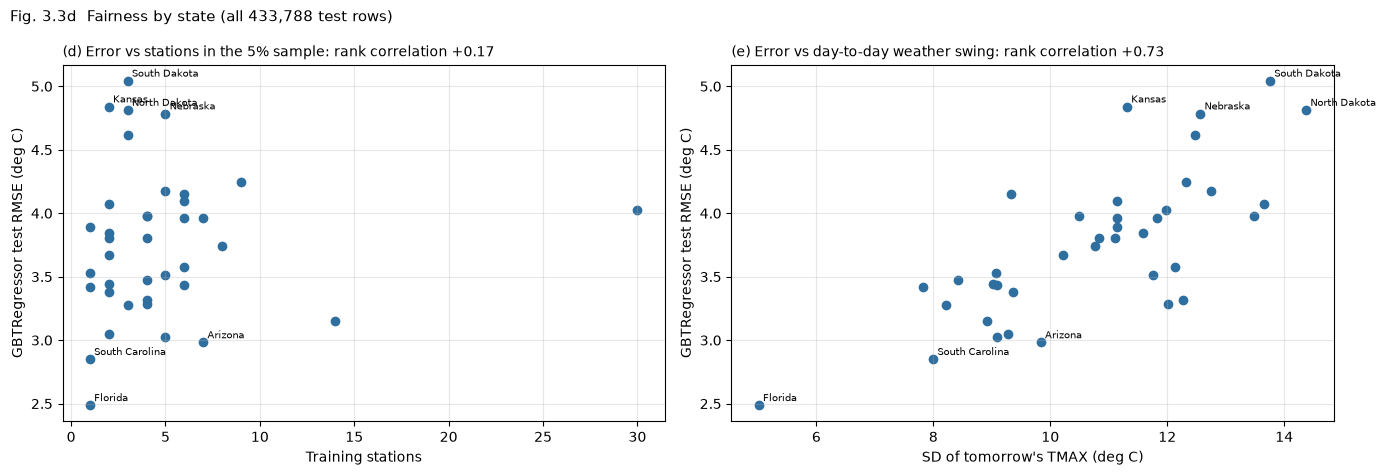

saved: task3/figures/task3_fairness.png
Table 3.3  Explainability and fairness (answer-sheet layout)


,Item,Value
0,Method used (SHAP or LIME),SHAP - exact path-dependent TreeSHAP on the sa...
1,Model explained,GBTRegressor (60 trees) - recommended in Task 2
2,Top five features,1. TMAX 2. TMAX_roll7 3. doy_cos 4. TOBS 5. PRCP
3,Named bias risk,Extreme-weather and regional bias: on test day...


saved: task3/results/task3_results.json [explainability]
saved: results/task3.json [explainability]


In [15]:

# ==============================================================================
# 3.3.3  Error by state and on extreme days (all test rows), Fig. 3.3d and results/task3.json
# REF: Week 5 lecture "Ethics, Bias, and Fairness in ML" (group error disparity); Task 1 ethics note (station coverage)
## AI: group-error tables, rank correlations and the summary table written with AI assistance
# ==============================================================================
STATE_NAMES = {"01": "Alabama", "02": "Arizona", "03": "Arkansas", "04": "California", "05": "Colorado",
               "06": "Connecticut", "07": "Delaware", "08": "Florida", "09": "Georgia", "10": "Idaho", "11": "Illinois",
               "12": "Indiana", "13": "Iowa", "14": "Kansas", "15": "Kentucky", "16": "Louisiana", "17": "Maine",
               "18": "Maryland", "19": "Massachusetts", "20": "Michigan", "21": "Minnesota", "22": "Mississippi",
               "23": "Missouri", "24": "Montana", "25": "Nebraska", "26": "Nevada", "27": "New Hampshire",
               "28": "New Jersey", "29": "New Mexico", "30": "New York", "31": "North Carolina", "32": "North Dakota",
               "33": "Ohio", "34": "Oklahoma", "35": "Oregon", "36": "Pennsylvania", "37": "Rhode Island",
               "38": "South Carolina", "39": "South Dakota", "40": "Tennessee", "41": "Texas", "42": "Utah",
               "43": "Vermont", "44": "Virginia", "45": "Washington", "46": "West Virginia", "47": "Wisconsin",
               "48": "Wyoming", "50": "Alaska", "51": "Hawaii", "OTHER": "other networks"}
FAIR_MODELS = list(dict.fromkeys([EXPLAINED, "RandomForestRegressor"]))
train_cover = (train_raw.groupBy("state_code").agg(F.countDistinct("ID").alias("Training stations"),
                                                   F.count(F.lit(1)).alias("Training rows")).toPandas())
BY_STATE, EXTREMES, CORR = {}, [], {}
for n in FAIR_MODELS:
    pred = (PipelineModel.load(spark_path(MODEL_PATHS[n])).transform(test_raw)
            .select("ID", "state_code", TARGET, "prediction").persist(StorageLevel.MEMORY_AND_DISK))
    e, y = F.col(TARGET) - F.col("prediction"), F.col(TARGET)
    st = (pred.groupBy("state_code").agg(F.count(F.lit(1)).alias("Test rows"),
                                         F.sqrt(F.avg(e * e)).alias("RMSE"), F.avg(e).alias("Bias"),
                                         F.stddev(y).alias("SD of tomorrow's TMAX")).toPandas()
          .merge(train_cover, on="state_code", how="left"))
    st.insert(1, "State", st["state_code"].map(STATE_NAMES).fillna("?"))
    st = st.sort_values("RMSE").reset_index(drop=True).round(3)
    BY_STATE[n] = st
    rank_corr = lambda a, b: round(float(st[a].rank().corr(st[b].rank())), 3)
    CORR[n] = {"stations_vs_rmse": rank_corr("Training stations", "RMSE"),
               "weather_swing_vs_rmse": rank_corr("SD of tomorrow's TMAX", "RMSE"),
               "worst_over_best_rmse": round(float(st["RMSE"].max() / st["RMSE"].min()), 2)}
    a = pred.agg(*[F.avg(F.when(cond, e)).alias(k) for k, cond in
                   (("hot_35", y >= 35), ("hot_32", y >= 32), ("cold_0", y <= 0), ("cold_m10", y <= -10))],
                 *[F.sum(cond.cast("int")).alias("n_" + k) for k, cond in
                   (("hot_35", y >= 35), ("hot_32", y >= 32), ("cold_0", y <= 0), ("cold_m10", y <= -10))],
                 F.avg(e).alias("all")).first()
    for k, label in (("hot_35", "Tomorrow >= 35 deg C"), ("hot_32", "Tomorrow >= 32 deg C"),
                     ("cold_0", "Tomorrow <= 0 deg C"), ("cold_m10", "Tomorrow <= -10 deg C")):
        EXTREMES.append({"Model": n, "Days": label, "Test days": int(a["n_" + k]), "Bias (actual - forecast, deg C)":
                         round(a[k], 3), "Bias on all days": round(a["all"], 3)})
    pred.unpersist()

st = BY_STATE[EXPLAINED]
show(pd.concat([st.head(5), st.tail(5)]), f"Table 3.3b  {EXPLAINED}: the 5 best and 5 worst states by test RMSE "
     f"({len(st)} groups)")
EXTREME_TABLE = pd.DataFrame(EXTREMES)
show(EXTREME_TABLE, "Table 3.3c  Bias on the days warnings are issued for (positive = forecast too cold)")
for n in FAIR_MODELS:
    c = CORR[n]
    print(f"{n:<22} worst/best state RMSE {c['worst_over_best_rmse']}x | rank correlation with RMSE: "
          f"training stations {c['stations_vs_rmse']:+.2f}, day-to-day weather swing {c['weather_swing_vs_rmse']:+.2f}")
for n, df_ in BY_STATE.items():
    df_.to_csv(RES_DIR / f"task3_fairness_by_state_{n}.csv", index=False)
EXTREME_TABLE.to_csv(RES_DIR / "task3_fairness_extremes.csv", index=False)

# ---- Fig. 3.3d: does the state error follow the station count or the weather? ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, xcol, title in ((ax1, "Training stations", "(d) Error vs stations in the 5% sample"),
                        (ax2, "SD of tomorrow's TMAX", "(e) Error vs day-to-day weather swing")):
    ax.scatter(st[xcol], st["RMSE"], color="#2f6f9f")
    for _, r in pd.concat([st.head(3), st.tail(4)]).iterrows():
        ax.annotate(r["State"], (r[xcol], r["RMSE"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel(xcol + (" (deg C)" if "SD" in xcol else "")); ax.set_ylabel(f"{EXPLAINED} test RMSE (deg C)")
    key = "stations_vs_rmse" if "stations" in xcol else "weather_swing_vs_rmse"
    ax.set_title(f"{title}: rank correlation {CORR[EXPLAINED][key]:+.2f}", loc="left", fontsize=10); ax.grid(alpha=0.3)
fig.suptitle("Fig. 3.3d  Fairness by state (all 433,788 test rows)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "task3_fairness.png", dpi=150, bbox_inches="tight"); plt.show()
print("saved:", rel(FIG_DIR / "task3_fairness.png"))

# ---- Table 3.3 in the answer-sheet layout ----
ext = EXTREME_TABLE.set_index(["Model", "Days"])["Bias (actual - forecast, deg C)"]
worst, best = st.iloc[-1], st.iloc[0]
BIAS_RISK = (f"Extreme-weather and regional bias: on test days >= 35 deg C the forecast is "
             f"{ext[(EXPLAINED, 'Tomorrow >= 35 deg C')]:+.1f} deg C too cold and on days <= -10 deg C "
             f"{-ext[(EXPLAINED, 'Tomorrow <= -10 deg C')]:.1f} deg C too warm; state RMSE ranges from {best['RMSE']:.2f} "
             f"({best['State']}) to {worst['RMSE']:.2f} deg C ({worst['State']}), following weather swing "
             f"(rank corr. {CORR[EXPLAINED]['weather_swing_vs_rmse']:+.2f}) more than station count "
             f"({CORR[EXPLAINED]['stations_vs_rmse']:+.2f})")
TABLE_33 = pd.DataFrame({"Item": ["Method used (SHAP or LIME)", "Model explained", "Top five features", "Named bias risk"],
                         "Value": [f"SHAP - exact path-dependent TreeSHAP on the saved Spark trees ({len(X_EX):,} test days; "
                                   f"additivity error {ADDITIVITY:.0e} deg C)",
                                   f"{EXPLAINED} ({len(tree_model.trees)} trees) - recommended in Task 2",
                                   " ".join(f"{i}. {f}" for i, f in enumerate(TOP5, 1)), BIAS_RISK]})
show(TABLE_33, "Table 3.3  Explainability and fairness (answer-sheet layout)")
TABLE_33.to_csv(RES_DIR / "task3_explainability.csv", index=False)

if "save_task3" not in globals():                      # earlier sections were not run in this session
    def save_task3(section, payload):
        header = {"task": 3, "notebook": NOTEBOOK, "quick_test": QUICK_TEST, "student": task1.get("student"),
                  "pool_reference": task1.get("pool_reference"), "problem_type": "regression", "target_col": TARGET,
                  "input_contract": ["results/task1.json#handoff", "results/task2.json#models"],
                  "executor_config": EXECUTOR_CONFIG}
        targets = [RES_DIR / "task3_results.json"] + ([] if QUICK_TEST else [ROOT / "results" / "task3.json"])
        for path in targets:
            data = json.loads(path.read_text()) if path.exists() else {}
            if data and data.get("notebook") != NOTEBOOK:
                print(f"NOT overwritten: {rel(path)} was written by another notebook"); continue
            data.update(header); data[section] = payload
            path.write_text(json.dumps(data, indent=2, default=str))
            print("saved:", rel(path), f"[{section}]")

save_task3("explainability", {
    "method": "SHAP: exact path-dependent TreeSHAP computed from the saved Spark trees (toDebugString); node covers "
              "from a 2% training sample; state one-hots grouped",
    "model_explained": EXPLAINED, "explained_rows": int(len(X_EX)), "background_rows": int(len(X_BG)),
    "base_value": round(BASE, 4), "additivity_max_error": ADDITIVITY, "shap_seconds": SHAP_S,
    "top_five_features": TOP5, "importance": SHAP_TABLE.to_dict("records"),
    "fairness": {"by_state": {n: d.to_dict("records") for n, d in BY_STATE.items()},
                 "rank_correlations": CORR, "extremes": EXTREME_TABLE.to_dict("records")},
    "named_bias_risk": BIAS_RISK,
})